# Same data, different story

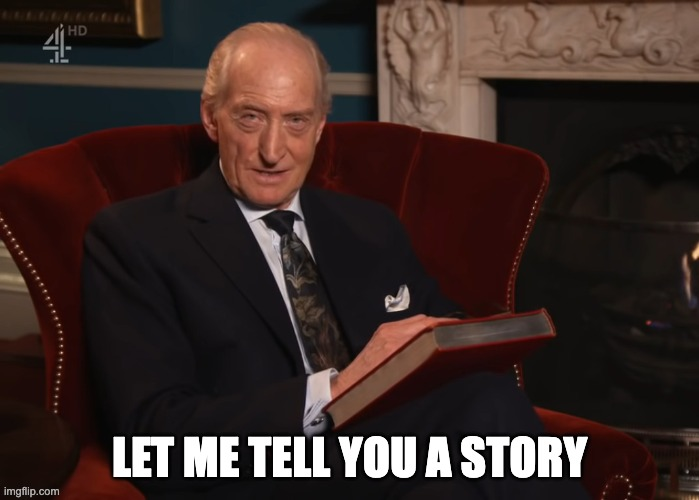

## 1. Houston, we need a kernel
1. Install [Miniconda](https://docs.conda.io/en/latest/miniconda.html)
2. In a terminal, in this folder: `conda env create -f environment.yml`, then `conda activate jacs-plotting`
3. Then: `python -m ipykernel install --user --name jacs-plotting --display-name "JACS plotting"`
4. In [Jupyter](https://jupyter.org/), choose the **JACS plotting** kernel.
5. In [VS Code](https://code.visualstudio.com/), pick the JACS plotting kernel from the kernel selector at the top right of the notebook.

In [1]:
# Check your setup: run this cell. It should print "All good".
import importlib, pathlib

missing = []
for mod in ["numpy", "matplotlib", "matplotlib.colors", "healpy", "corner", "seaborn",
            "astropy", "astropy.io.fits", "astropy.wcs", "astropy.visualization"]:
    try:
        m = importlib.import_module(mod)
        if hasattr(m, "__version__"):
            print(f"{mod:12s} {m.__version__}")
    except ImportError as e:
        missing.append(f"package {mod} ({e})")
for f in ["data/HorseHead.fits", "data/chains_thinned.npz", "data/haslam_nside256.fits"]:
    if not pathlib.Path(f).is_file():
        missing.append(f"data file {f}")

if missing:
    print("⚠️ Not ready yet. Missing:\n  " + "\n  ".join(missing))
    print("Pair up with a neighbour, pip install the package or show this message to the session overlord.")
else:
    print("🎉 All good! Kernel ready, packages found, data in place. Grab your keyboards, it's time to lock in.")

numpy        2.4.6
matplotlib   3.11.2
healpy       1.20.1
corner       2.3.0
seaborn      0.13.2
astropy      8.0.2
🎉 All good! Kernel ready, packages found, data in place. Grab your keyboards, it's time to lock in.


## 2. Choose your fighter

How would you choose a plot and why? 

Check this out: [from-data-to-viz](https://www.data-to-viz.com/)

## 3. Bad Plot, Good Plot

What makes a bad plot and what makes a good plot? Can you spot the plot crimes before you send them off?

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import healpy as hp
import corner
import seaborn as sns
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import simple_norm

rng = np.random.default_rng(42)

---
### a. 1D plot (1D power spectrum)

The [Haslam all-sky map at 408 MHz](https://lambda.gsfc.nasa.gov/product/foreground/fg_2014_haslam_408_info.html) (radio emission, mostly Galactic synchrotron; brightness temperature in K). We measure its angular power spectrum.

(`demo1_power_spectrum_executed.ipynb` goes further, with a cross-spectrum that changes sign.)

In [3]:
# Data: the Haslam sky map, 408 MHz, publically available on LAMBDA
m = hp.read_map("data/haslam_nside256.fits")
cl = hp.anafast(m, lmax=700)                  # angular power spectrum, K^2
ell = np.arange(cl.size)

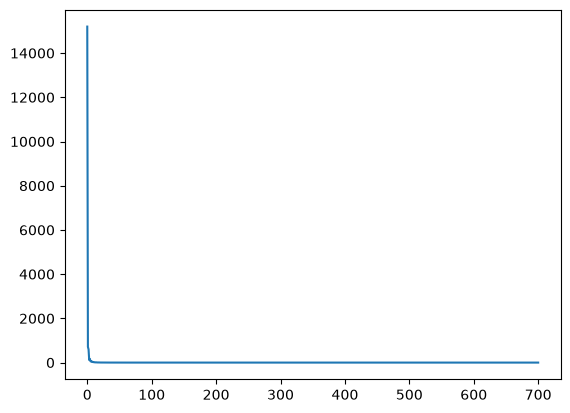

In [4]:
plt.plot(cl)
plt.show()

**Ask the room:** what does this spectrum tell you? What is on the axes?

<details>
<summary>Presenter notes</summary>

**What is wrong with the bad plot (the better version fixes these four):**

- $C_\ell$ falls steeply, roughly as a power law, so on linear axes everything above $\ell \sim 20$ is squashed flat. Use log axes, and plot $D_\ell = \ell(\ell+1)C_\ell/2\pi$ so the shape is readable.
- No axis labels, no units (K$^2$).
- $\ell = 0, 1$ (monopole and dipole) are included. They say nothing about structure on the sky, so start the plot at $\ell = 2$.

**What the best version adds (stretch / take-home):**

- Every single $\ell$ is plotted, which is noisy: bin it in log-spaced bins.
- No error bars. The Gaussian sample-variance bars are only a rough guide, because foregrounds are not Gaussian.
- Nothing marks where the map stops being reliable: the 56′ beam smooths away structure above $\ell \approx 120$, so the drop there is the telescope, not the sky. Shade that region.

**Say out loud:** a fall at high $\ell$ in this plot is not a discovery. It is the beam.

</details>

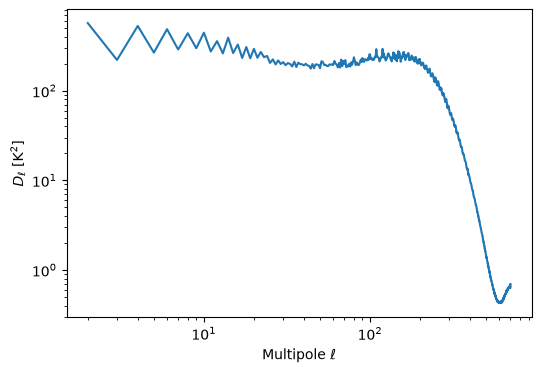

In [5]:
ell = np.arange(len(cl))
D = ell * (ell + 1) * cl / (2 * np.pi)          # the usual scaling, so the plot is flat-ish, not a cliff

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ell[2:], D[2:])                         # log-log; drop the monopole and dipole
ax.set_xlabel(r"Multipole $\ell$")
ax.set_ylabel(r"$D_\ell\ [\mathrm{K}^2]$")
plt.show()

### Better: $D_\ell$ on log axes, binned, with errors and the beam scale

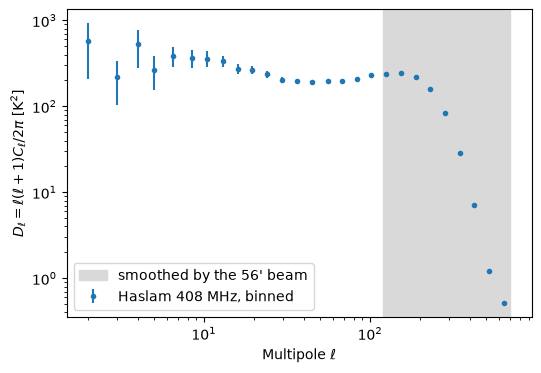

In [5]:
D = ell * (ell + 1) * cl / (2 * np.pi)                       # K^2

# log-spaced bins from ell = 2 (monopole and dipole dropped)
edges = np.unique(np.geomspace(2, ell.max() + 1, 30).astype(int))
ell_b = 0.5 * (edges[1:] + edges[:-1] - 1)
D_b = np.array([D[a:b].mean() for a, b in zip(edges[:-1], edges[1:])])
n_modes = np.array([(2 * ell[a:b] + 1).sum() for a, b in zip(edges[:-1], edges[1:])])
D_err = D_b * np.sqrt(2 / n_modes)            # Gaussian sample variance: only a rough guide, foregrounds are not Gaussian
ell_beam = np.sqrt(np.log(2)) / (np.radians(56 / 60) / np.sqrt(8 * np.log(2)))   # ~120: the 56' beam halves the power here

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(ell_b, D_b, yerr=D_err, fmt="o", ms=3, label="Haslam 408 MHz, binned")
ax.axvspan(ell_beam, ell.max(), color="0.85", label="smoothed by the 56' beam")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Multipole $\ell$")
ax.set_ylabel(r"$D_\ell = \ell(\ell+1)C_\ell/2\pi\ [\mathrm{K}^2]$")
ax.legend()
plt.show()

---
# 2. A fit that looks perfect

Toy data: 20 measurements over two decades in $x$, each with a 5% error, fitted with a pure power law.

In [6]:
rng = np.random.default_rng(42)
x = np.logspace(0, 2, 20)
x0, A, beta, C = 10, 50, -2.0, 0.07
y_true = A * (x / x0) ** beta * np.exp(C * np.log(x / x0) ** 2)   # C > 0: mild curvature
sigma = 0.05 * y_true
y = y_true + rng.normal(0, sigma)

# pure power law = straight line in log space
index, log_norm = np.polyfit(np.log(x), np.log(y), 1, w=y / sigma)
model = np.exp(log_norm) * x ** index
resid = (y - model) / sigma
chi2_dof = np.sum(resid ** 2) / (len(x) - 2)

### Looks fine

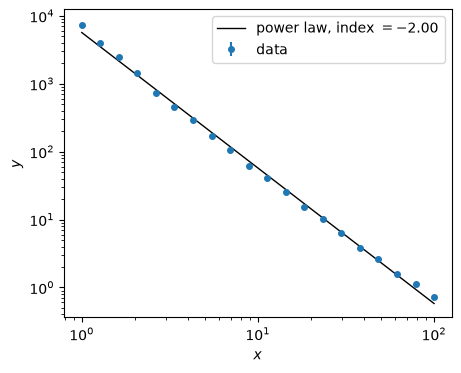

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.errorbar(x, y, yerr=sigma, fmt="o", ms=4, label="data")
ax.plot(x, model, "k-", lw=1, label=rf"power law, index $= {index:.2f}$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.legend()
plt.show()

**Ask the room:** is this a good fit?

<details>
<summary>Presenter notes</summary>

- On log-log axes a 20% deviation is tiny next to four decades in $y$. The eye can't see it.
- A line passing through the points is not a test of the fit. Look at the residuals.
- $\chi^2/\mathrm{dof} \approx 7$: the power law is rejected, even though the picture says it fits.
- The quoted index comes from the wrong model, so its precision means little.

</details>

### Better: add a residual panel and quote $\chi^2/\mathrm{dof}$

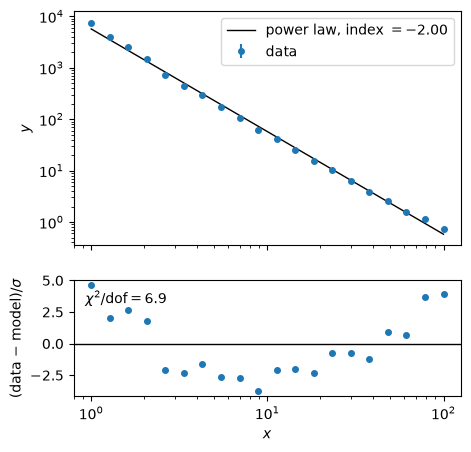

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(5, 5),
                               gridspec_kw={"height_ratios": [3, 1.5]})
ax1.errorbar(x, y, yerr=sigma, fmt="o", ms=4, label="data")
ax1.plot(x, model, "k-", lw=1, label=rf"power law, index $= {index:.2f}$")
ax1.set_yscale("log")
ax1.set_ylabel("$y$")
ax1.legend()

ax2.axhline(0, color="k", lw=1)
ax2.plot(x, resid, "o", ms=4)
ax2.set_xscale("log")
ax2.set_xlabel("$x$")
ax2.set_ylabel(r"(data $-$ model)$/\sigma$")
ax2.text(0.03, 0.8, rf"$\chi^2/\mathrm{{dof}} = {chi2_dof:.1f}$", transform=ax2.transAxes)
plt.show()

---
# 3. 2D power spectrum

A 20° × 20° patch of the same [Haslam map](https://lambda.gsfc.nasa.gov/product/foreground/fg_2014_haslam_408_info.html) near the North Polar Spur, cut out with a flat-sky (gnomonic) projection, and its 2D power spectrum $P(\ell_x, \ell_y)$. (A cylindrical $P(k_\perp, k_\parallel)$, as in 21cm work, needs many frequency channels; a single map only gives the two angular directions.)

In [9]:
m = hp.read_map("data/haslam_nside256.fits")                # same Haslam map as section a, K

# a 20 x 20 deg patch (flat-sky approximation), near the North Polar Spur
npix_side, reso = 200, 6.0                                   # pixels per side, arcmin per pixel
patch = np.asarray(hp.gnomview(m, rot=(30, 45), xsize=npix_side, reso=reso,
                               return_projected_map=True, no_plot=True), dtype=float)
P2d_raw = np.abs(np.fft.fft2(patch)) ** 2                    # what the FFT gives you straight away

dtheta = np.radians(reso / 60)                               # pixel size in radians
window = np.outer(np.hanning(npix_side), np.hanning(npix_side))   # taper the edges
F = np.fft.fftshift(np.fft.fft2((patch - patch.mean()) * window))
P2d = np.abs(F) ** 2 * dtheta**2 / (npix_side**2 * np.mean(window**2))   # K^2 sr, same units as C_ell
ell_xy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(npix_side, d=dtheta))
ell_beam = np.sqrt(np.log(2)) / (np.radians(56 / 60) / np.sqrt(8 * np.log(2)))   # ~120: the 56' beam halves the power here

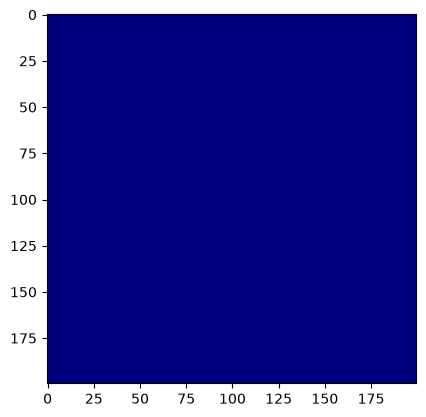

In [10]:
plt.imshow(P2d_raw, cmap="jet")
plt.show()

**Ask the room:** where is the power? Which scales are which?

<details>
<summary>Presenter notes</summary>

- `np.fft.fft2` puts $\ell = 0$ in the corners, not the centre. Use `np.fft.fftshift`.
- The map's mean was not subtracted, so the $\ell = 0$ pixel is so bright that everything else is the bottom colour of a linear scale. Subtract the mean and use a log colour scale.
- Axes are pixel indices, not $\ell_x, \ell_y$.
- No colour bar, so there is no way to read a value.
- The patch edges were not tapered, so the jump at the edges leaks power along the axes. Apply a window.
- `jet` again.

</details>

### Better: centred, mean removed, tapered, log colour scale, $\ell$ axes, beam scale marked

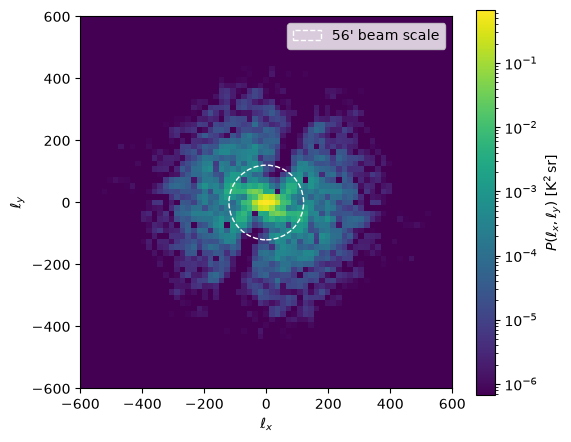

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(ell_xy, ell_xy, P2d, norm=LogNorm(vmin=P2d.max() * 1e-6), cmap="viridis")   # top 6 decades
ax.add_patch(plt.Circle((0, 0), ell_beam, fill=False, color="w", ls="--", label="56' beam scale"))
ax.set_xlim(-600, 600)
ax.set_ylim(-600, 600)
ax.set_aspect("equal")
ax.set_xlabel(r"$\ell_x$")
ax.set_ylabel(r"$\ell_y$")
fig.colorbar(im, label=r"$P(\ell_x, \ell_y)\ [\mathrm{K}^2\,\mathrm{sr}]$")
ax.legend(loc="upper right")
plt.show()

---
# 4. Histogram binning

Toy data: 300 measurements of a single quantity.

In [12]:
rng = np.random.default_rng(1)
x_h = np.concatenate([rng.normal(0, 1, 210), rng.normal(3, 1, 90)])   # 70/30 mix, 3 sigma apart

### Looks fine

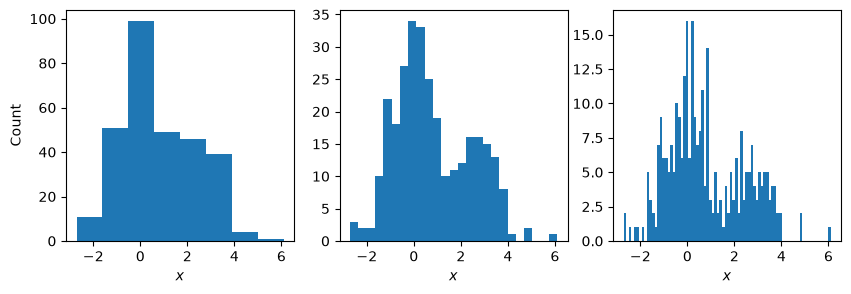

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, n_bins in zip(axes, [8, 25, 80]):
    ax.hist(x_h, bins=n_bins, range=(x_h.min(), x_h.max()))
    ax.set_xlabel("$x$")
axes[0].set_ylabel("Count")
plt.show()

**Ask the room:** is this one population or two?

<details>
<summary>Presenter notes</summary>

- Same 300 points in each panel. Only the number of bins changes (8, 25, 80).
- Coarse bins merge the two groups into one skewed peak. Medium bins show two. Fine bins show mostly noise.
- None of the three is wrong. The answer just shouldn't depend on a plotting choice.
- If a feature appears or disappears when the binning changes, the plot isn't evidence for it.

</details>

### Better: an ECDF (no binning) next to a histogram with a stated, rule-based bin width

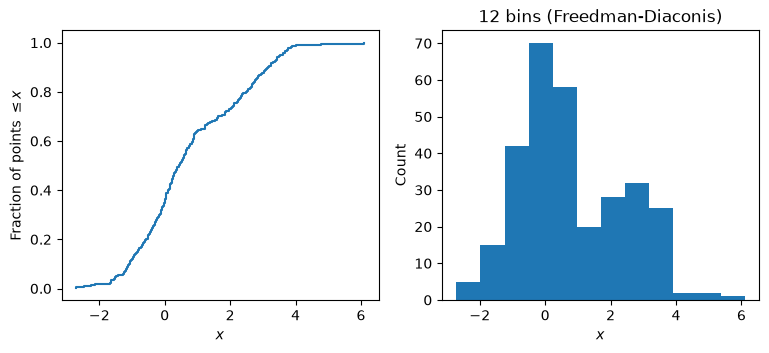

In [14]:
xs = np.sort(x_h)
edges = np.histogram_bin_edges(x_h, bins="fd")    # Freedman-Diaconis bin width

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post")   # steep = dense, flatter in between = gap
ax1.set_xlabel("$x$")
ax1.set_ylabel(r"Fraction of points $\leq x$")
ax2.hist(x_h, bins=edges)
ax2.set_xlabel("$x$")
ax2.set_ylabel("Count")
ax2.set_title(f"{len(edges) - 1} bins (Freedman-Diaconis)")
plt.show()

---
# 5. Heatmap

Six $H_0$ values from six probes, and the difference between every pair. **These numbers are synthetic** (drawn with a fixed seed), loosely inspired by the real spread; they are not real measurements.

In [15]:
rng_h = np.random.default_rng(7)
probes = np.array(["CMB", "BAO + BBN", "TRGB", "Cepheids", "Lensing delays", "Masers"])
h0 = np.array([67.5, 68.3, 69.8, 73.0, 72.7, 73.4]) + rng_h.normal(0, 0.3, 6)   # km/s/Mpc, synthetic
h0_err = rng_h.uniform(0.5, 1.5, 6)                                             # 1 sigma, synthetic

D = h0[:, None] - h0[None, :]                              # D[i, j] = H0_i - H0_j
S = np.sqrt(h0_err[:, None] ** 2 + h0_err[None, :] ** 2)    # combined uncertainty
shuffled = rng_h.permutation(6)

Default colormap, shuffled order, index ticks and every pair shown twice. You can't tell which probe is which, or which colour means zero.

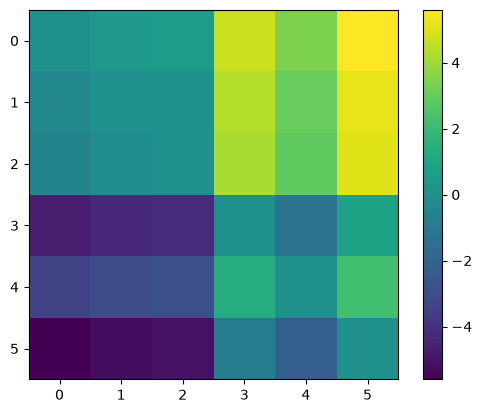

In [16]:
plt.imshow(D[np.ix_(shuffled, shuffled)])
plt.colorbar()
plt.show()

### Better: diverging colormap centred on zero, labels, each pair once
A signed difference needs a diverging colormap centred on its meaningful zero, and each pair only needs to appear once. The order is still random, so any structure is hard to see.

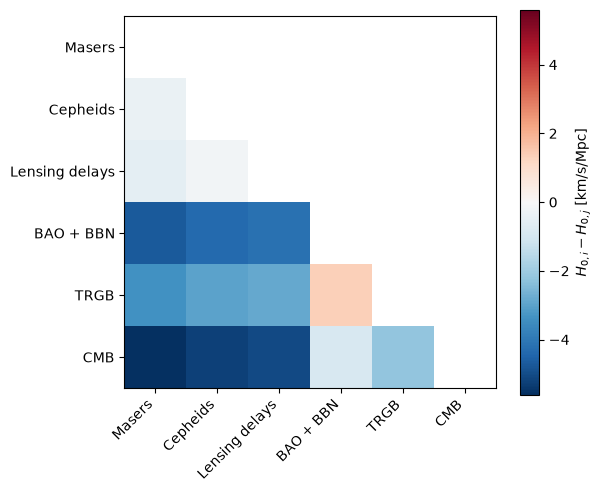

In [17]:
Dsh = D[np.ix_(shuffled, shuffled)]
lower = np.tril(np.ones((6, 6), bool), k=-1)       # below the diagonal: each pair once
vmax = np.abs(D).max()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(np.where(lower, Dsh, np.nan), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(6), probes[shuffled], rotation=45, ha="right")
ax.set_yticks(range(6), probes[shuffled])
fig.colorbar(im, label=r"$H_{0,i} - H_{0,j}$ [km/s/Mpc]")
plt.show()

### Best: sorted by $H_0$, annotated
Sorted by $H_0$, the two groups of probes show up as blocks, so row and column order decides what you can see. Heatmaps are weak at exact numbers, so each cell is annotated; outlined cells differ by less than their combined $1\sigma$.

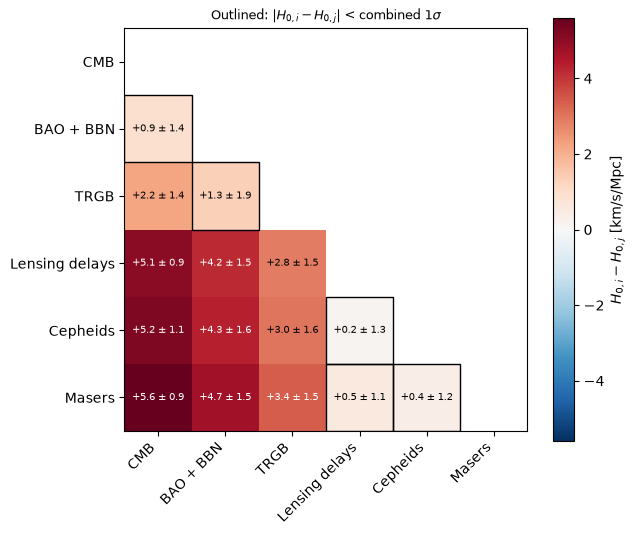

In [18]:
srt = np.argsort(h0)
Ds, Ss = D[np.ix_(srt, srt)], S[np.ix_(srt, srt)]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(np.where(lower, Ds, np.nan), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
for i, j in zip(*np.nonzero(lower)):
    colour = "white" if abs(Ds[i, j]) > 0.6 * vmax else "black"
    ax.text(j, i, f"{Ds[i, j]:+.1f} ± {Ss[i, j]:.1f}", ha="center", va="center", fontsize=7, color=colour)
    if abs(Ds[i, j]) < Ss[i, j]:                 # consistent within combined 1 sigma
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="k", lw=1))
ax.set_xticks(range(6), probes[srt], rotation=45, ha="right")
ax.set_yticks(range(6), probes[srt])
ax.set_title(r"Outlined: $|H_{0,i} - H_{0,j}|$ < combined $1\sigma$", fontsize=9)
fig.colorbar(im, label=r"$H_{0,i} - H_{0,j}$ [km/s/Mpc]")
plt.show()

---
# 6. Corner plots and convergence

## Visualising convergence

Same sampler, stopped early versus run to the end. Real Gibbs-sampler output (12 complex parameters, thinned by 10); we plot the real parts of the first four, and cut each run into 4 equal consecutive segments that we treat as chains.

In [19]:
d = np.load("data/chains_thinned.npz")
thin = int(d["thin"])
run = d["chains"][:, :, :4].reshape(-1, 4)          # the whole run in time order: Re theta_0..theta_3
labels_c = list(d["names"][:4])
n_chains = 4
chain_colours = [f"C{c}" for c in range(n_chains)]  # one colour per chain, used in every plot below

N_EARLY = 5000   # raw samples: the sampler stopped early (= 500 thinned samples)
early = run[: N_EARLY // thin].reshape(n_chains, -1, 4)   # 4 equal consecutive segments
full = run.reshape(n_chains, -1, 4)                         # run to the end: 4 segments of 6,250
BURN_IN = 50     # thinned samples cut from the start of every chain; chain 0 settles after ~50

In [20]:
def split_rhat(x):
    """Split R-hat for one parameter; x has shape (chain, sample)."""
    n = x.shape[1] // 2
    x = np.concatenate([x[:, :n], x[:, n:2 * n]])       # cut every chain into two halves
    W = x.var(axis=1, ddof=1).mean()                     # within-chain variance
    B = n * x.mean(axis=1).var(ddof=1)                   # between-chain variance
    return np.sqrt(((n - 1) / n * W + B / n) / W)

def plot_traces(ch, title):
    step = np.arange(1, ch.shape[1] + 1)
    fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 7))
    for k, ax in enumerate(axes):
        for c in range(n_chains):
            ax.plot(step, ch[c, :, k], color=chain_colours[c], lw=0.6, label=f"chain {c}")
        ax.axvline(BURN_IN, color="k", ls="--", lw=1)
        ax.set_ylabel(labels_c[k])
    axes[0].set_title(title)
    axes[0].legend(ncol=4, fontsize=8, loc="lower right")
    axes[-1].set_xscale("log")                           # log axis so the short burn-in is visible
    axes[-1].set_xlabel(f"Sample in chain (thinned by {thin})")
    plt.show()

def plot_kdes(ch, title):
    kept = ch[:, BURN_IN:, :]
    chain_id = np.repeat([f"chain {c}" for c in range(n_chains)], kept.shape[1])
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
    for k, ax in enumerate(axes):
        sns.kdeplot(x=kept[:, :, k].ravel(), hue=chain_id, palette=chain_colours, ax=ax, legend=(k == 0))
        ax.set_xlabel(labels_c[k])
        ax.set_title(rf"split $\hat R$: {split_rhat(ch[:, :, k]):.3f} with burn-in, "
                     f"{split_rhat(kept[:, :, k]):.3f} after cut", fontsize=9)
    fig.suptitle(f"{title} (KDEs after the burn-in cut)", y=1.04)
    plt.show()

The sampler stopped after 5,000 samples, with every sample from all four chains pooled into one corner plot. It looks clean, and the titles quote tidy medians and errors.

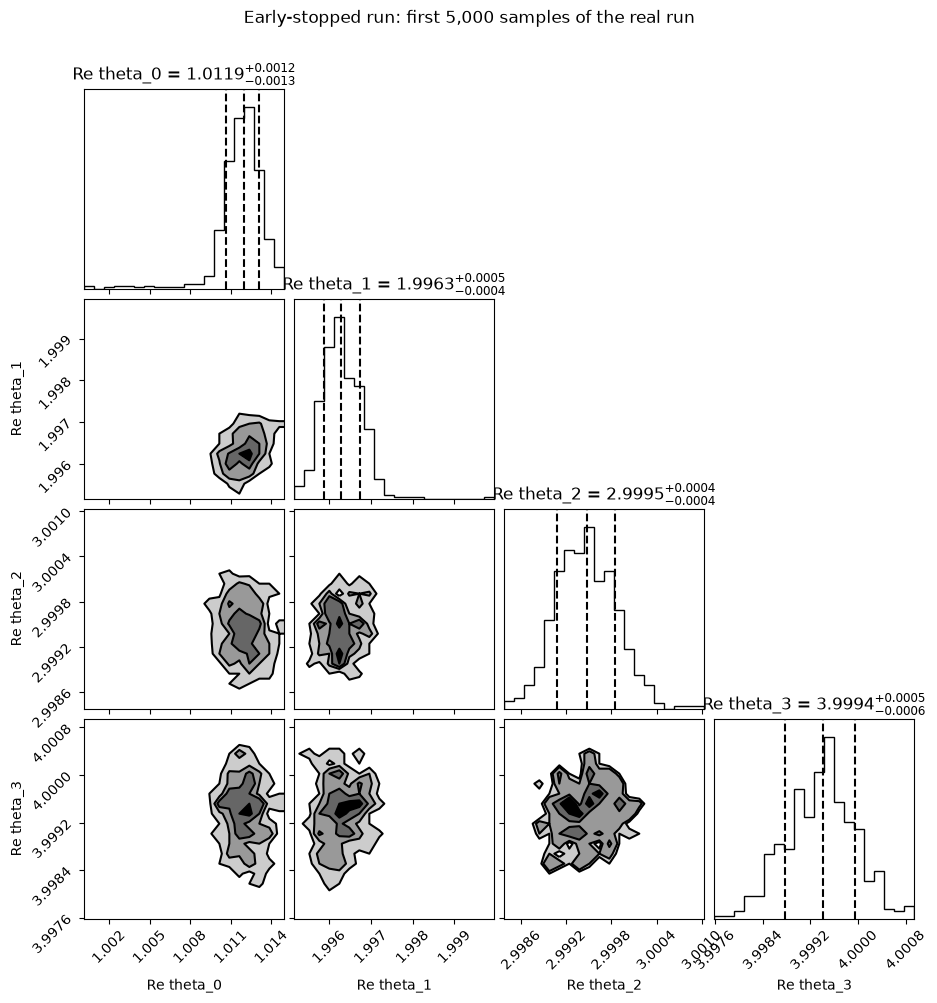

In [21]:
fig = corner.corner(early.reshape(-1, 4), labels=labels_c,
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt=".4f",
                    plot_datapoints=False, fill_contours=True)
fig.suptitle(f"Early-stopped run: first {N_EARLY:,} samples of the real run", y=1.04)
plt.show()

### Better: trace plots
Would you trust this corner plot? Now look at the chains.

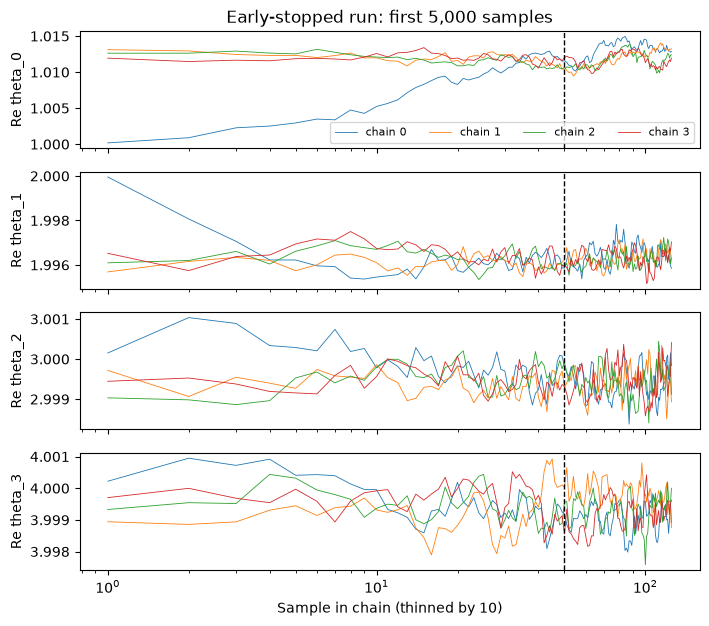

In [22]:
plot_traces(early, f"Early-stopped run: first {N_EARLY:,} samples")

### Better still: one distribution per chain, and split $\hat R$
Overlaid per-chain KDEs show whether the chains agree, and split $\hat R$ puts a number on it: it should be close to 1.00 (below about 1.01). Here it stays high even after the burn-in cut, because chains this short have not had time to mix.

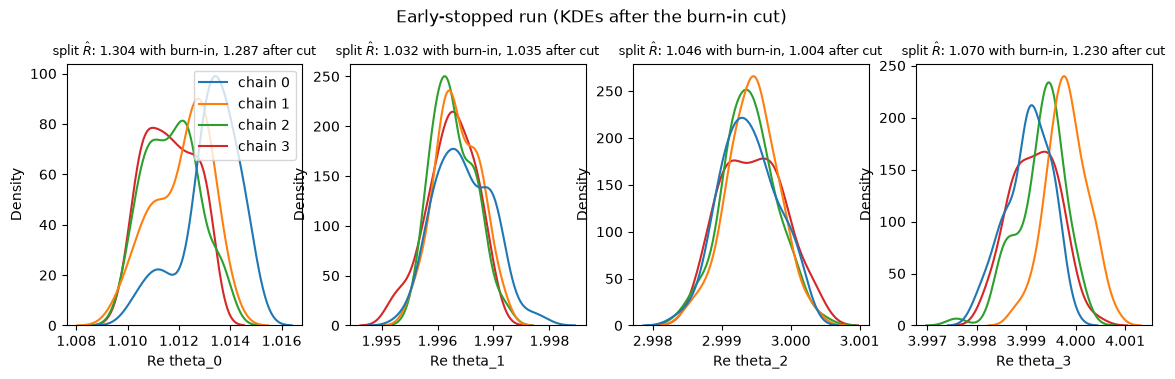

In [23]:
plot_kdes(early, "Early-stopped run")

The posterior barely moved here because this sampler converges fast, but you could not have known that from the corner plot. Checking R-hat takes one line.

### Best: what good looks like
The same sampler run to the end (all 25,000 thinned samples). Four consecutive segments of one run; ideally use independent chains from dispersed starts.

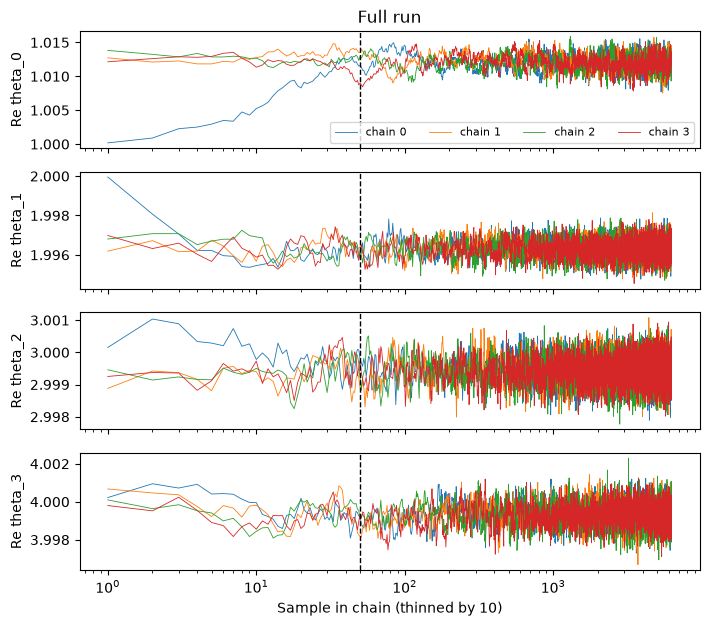

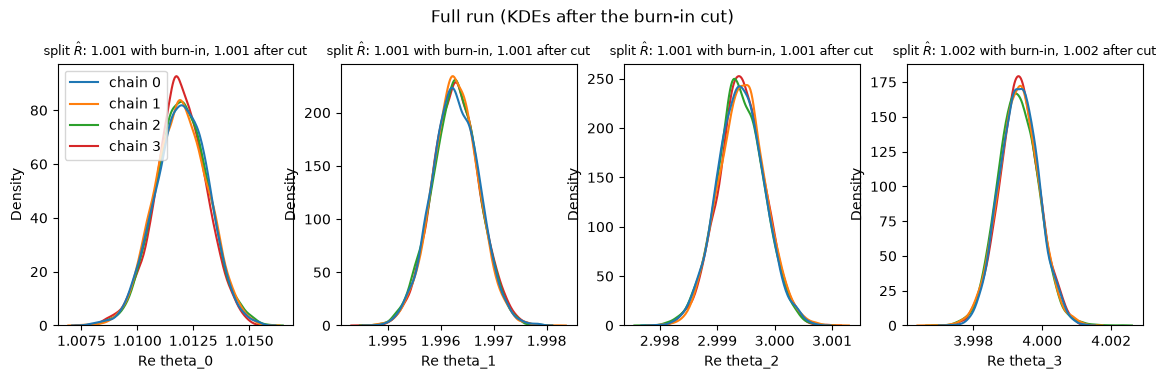

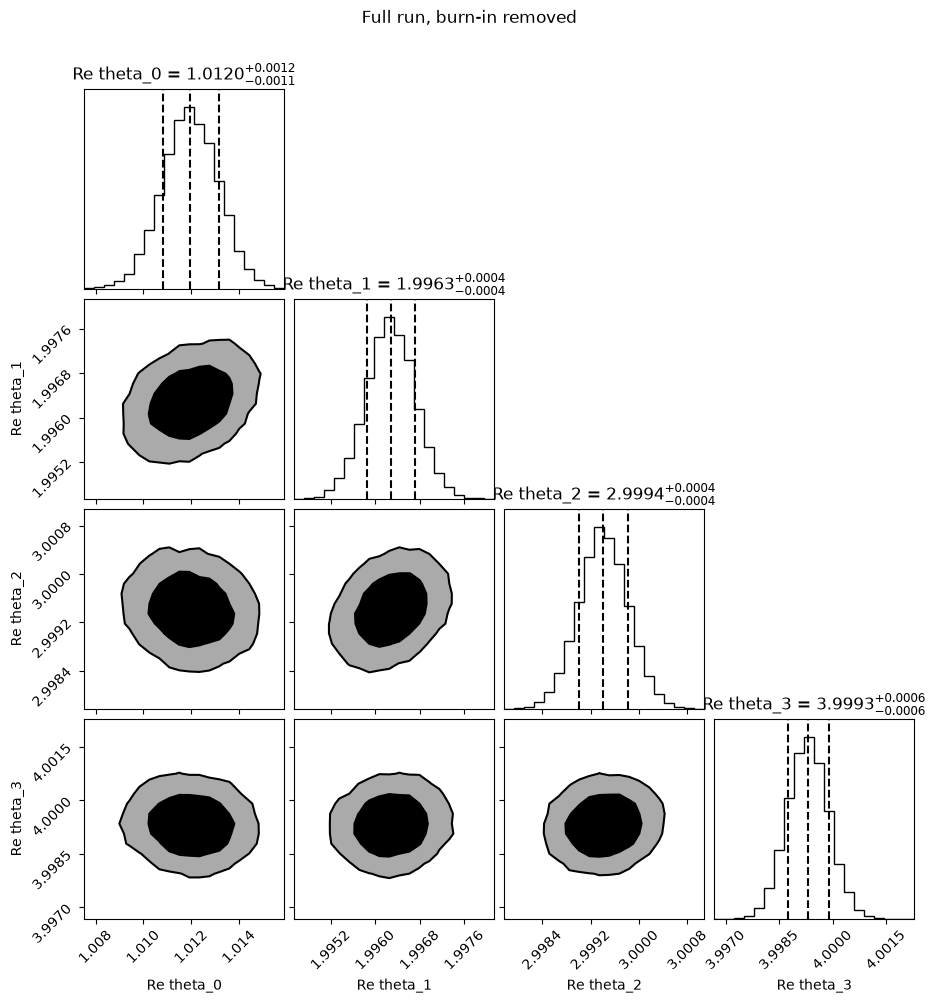

In [24]:
plot_traces(full, "Full run")
plot_kdes(full, "Full run")

fig = corner.corner(full[:, BURN_IN:, :].reshape(-1, 4), labels=labels_c, levels=(0.68, 0.95),
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt=".4f",
                    plot_datapoints=False, fill_contours=True)
fig.suptitle("Full run, burn-in removed", y=1.04)
plt.show()

---
## Corner plot

Toy posterior samples for four cosmological parameters (a correlated Gaussian).

In [25]:
names = [r"$\Omega_m$", r"$\sigma_8$", r"$h$", r"$n_s$"]
truth = np.array([0.31, 0.81, 0.674, 0.965])
sig = np.array([0.02, 0.015, 0.01, 0.006])
corr = np.array([[ 1.0, -0.8, -0.6,  0.0],
                 [-0.8,  1.0,  0.4,  0.1],
                 [-0.6,  0.4,  1.0,  0.3],
                 [ 0.0,  0.1,  0.3,  1.0]])
cov = corr * np.outer(sig, sig)
samples = rng.multivariate_normal(truth, cov, size=20000)

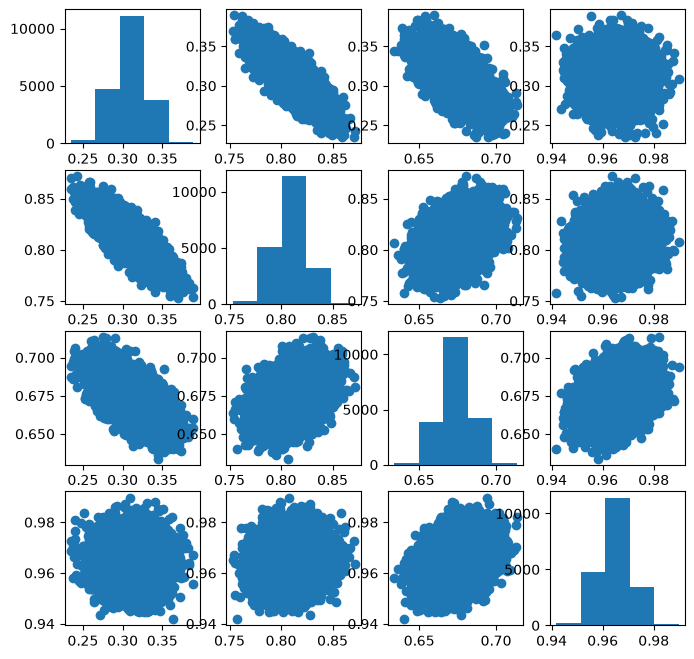

In [26]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i in range(4):
    for j in range(4):
        if i == j:
            axes[i, j].hist(samples[:, i], bins=5)
        else:
            axes[i, j].scatter(samples[:, j], samples[:, i])
plt.show()

**Ask the room:** what are the constraints on each parameter? Which ones are degenerate?

<details>
<summary>Presenter notes</summary>

- No parameter labels anywhere.
- The upper triangle repeats the lower triangle (transposed): half the figure is redundant.
- 20 000 opaque points become a solid blob. You can't see where the density peaks.
- `bins=5` hides the shape of the 1D marginals.
- No credible intervals or contour levels, no truth or fiducial values.
- Tick labels overlap, and the axes are not shared, so columns don't line up.

</details>

### Better: [`corner`](https://corner.readthedocs.io/), labels, contour levels, truths, quoted intervals

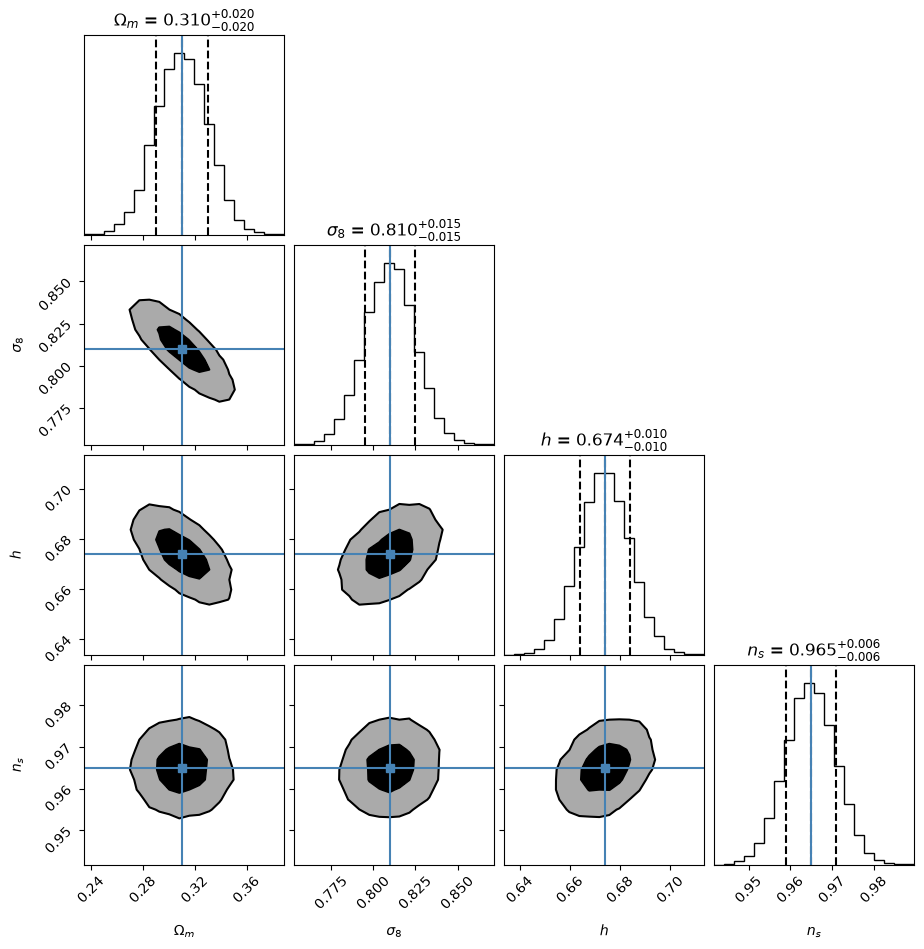

In [27]:
fig = corner.corner(samples, labels=names, truths=truth,
                    levels=(1 - np.exp(-0.5), 1 - np.exp(-2)),   # 1 and 2 sigma in 2D
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt=".3f",
                    plot_datapoints=False, fill_contours=True)
plt.show()

---
## A corner plot that looks professional but misleads

Toy data: posterior samples for four parameters. $\theta_3$ has a flat prior on $[0, 1]$.

In [28]:
rng = np.random.default_rng(42)
N = 20000
theta1 = rng.normal(0, 1, N)
theta2 = theta1 ** 2 + rng.normal(0, 0.5, N)      # banana-shaped degeneracy with theta1
theta3 = np.abs(rng.normal(0, 0.15, N))           # piles up against the prior edge at 0
theta4 = rng.normal(1, 0.2, N)
samples_b = np.column_stack([theta1, theta2, theta3, theta4])
names_b = [r"$\theta_1$", r"$\theta_2$", r"$\theta_3$", r"$\theta_4$"]

print(f"{N} samples; {np.mean(theta3 < 0.05):.0%} of theta_3 samples lie within 0.05 of the prior edge at 0")

20000 samples; 26% of theta_3 samples lie within 0.05 of the prior edge at 0


### Looks fine

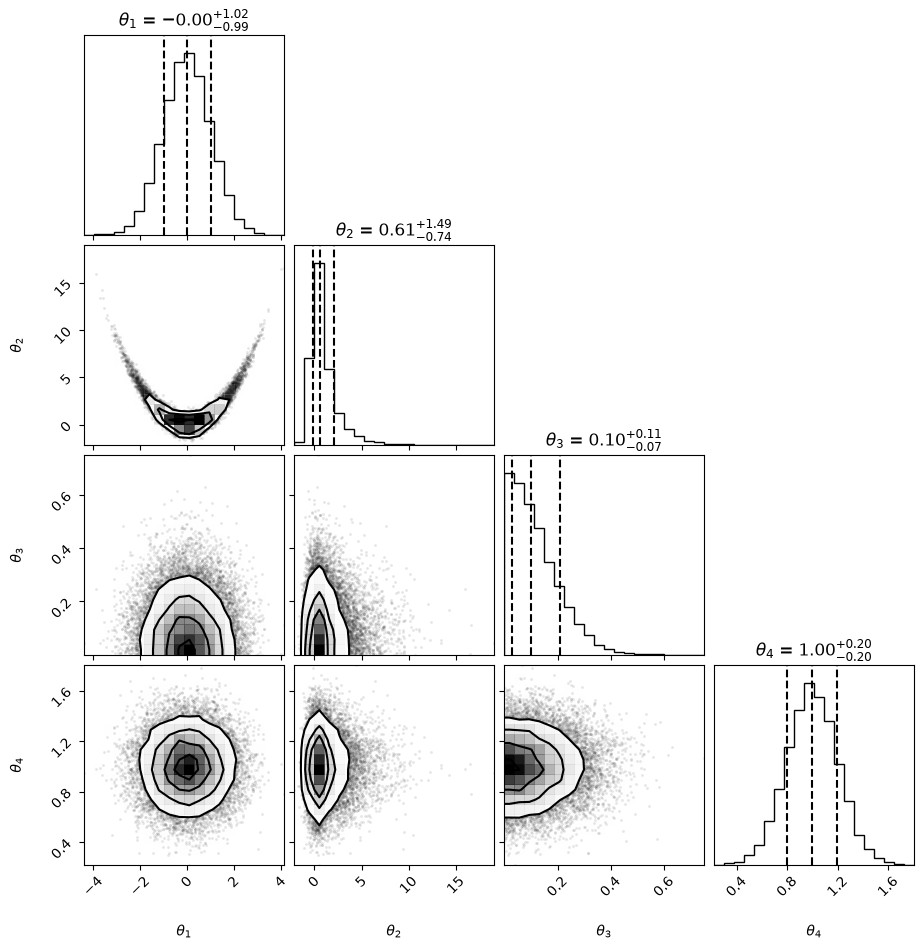

In [29]:
fig = corner.corner(samples_b, labels=names_b,
                    quantiles=[0.16, 0.5, 0.84], show_titles=True)
plt.show()

**Ask the room:** what does the title say about each parameter, and is it true?

<details>
<summary>Presenter notes</summary>

- The $\theta_3$ title reads like a detection (median $\pm$ error), but the posterior peaks at the prior edge. It is an upper limit.
- The tidy "median $^{+}_{-}$" titles suggest Gaussian errors and hide the banana in $\theta_1$-$\theta_2$.
- The 1D marginal of $\theta_1$ looks like a clean Gaussian. Only the 2D panel shows the degeneracy.
- The prior bounds on $\theta_3$ are not shown, so you can't tell that the edge is the prior and not the data.
- With no `levels` given, the contours are [corner](https://corner.readthedocs.io/)'s default "sigma" levels. Say which levels you plot.

</details>

### Better: prior bounds shown, stated contour levels, an upper limit for $\theta_3$

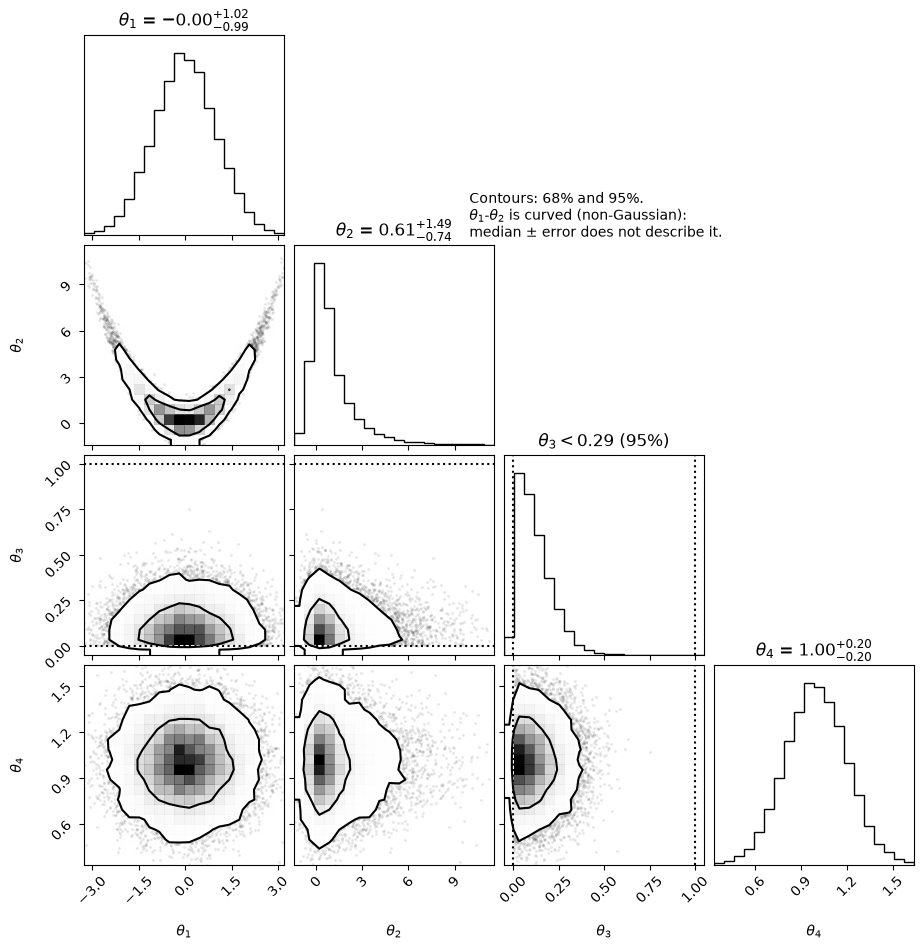

In [30]:
ul = np.percentile(theta3, 95)

fig = corner.corner(samples_b, labels=names_b, levels=(0.68, 0.95), show_titles=True,
                    range=[0.999, 0.999, (-0.05, 1.05), 0.999])
corner.overplot_lines(fig, [None, None, 0, None], color="k", ls=":")   # prior bounds on theta_3
corner.overplot_lines(fig, [None, None, 1, None], color="k", ls=":")
axes = np.array(fig.axes).reshape(4, 4)
axes[2, 2].set_title(rf"$\theta_3 < {ul:.2f}$ (95%)")
note = (r"Contours: 68% and 95%." "\n"
        r"$\theta_1$-$\theta_2$ is curved (non-Gaussian):" "\n"
        r"median $\pm$ error does not describe it.")
fig.text(0.5, 0.75, note)
plt.show()

---
# 7. Horsehead nebula image

The Horsehead Nebula, from a UK Schmidt photographic plate (the data is in `data/HorseHead.fits`).

In [31]:
image = fits.getdata("data/HorseHead.fits").astype(float)
header = fits.getheader("data/HorseHead.fits")
wcs = WCS(header)

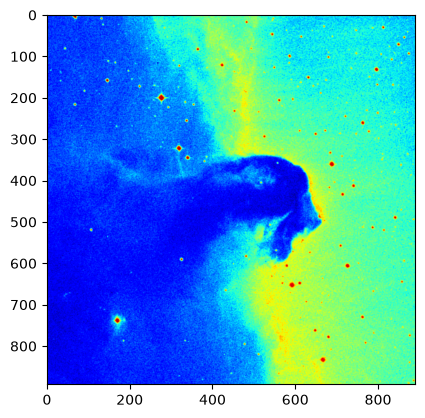

In [32]:
plt.imshow(image, cmap="jet")
plt.show()

**Ask the room:** is this the right way up? Where in the sky is it? How big is it?

<details>
<summary>Presenter notes</summary>

- `imshow` puts pixel (0, 0) at the top left, but FITS puts it at the bottom left. The image is upside down.
- Axes are pixel numbers. The header has a WCS, so use RA and Dec.
- A linear stretch: most of the nebula sits in a narrow range of values and looks flat.
- `jet` adds structure that isn't there. Single-band images usually look best in greyscale.
- No colour bar or units, and no scale or orientation.

</details>

### Better: the basic fixes
Right way up (`origin="lower"`), greyscale, labelled axes and a colour bar. But the bright stars still set the linear range, so the faint nebula is squeezed into a few dark grey levels.

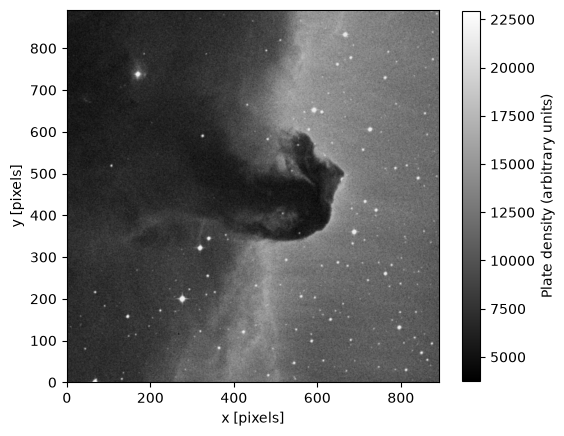

In [33]:
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(image, origin="lower", cmap="gray")   # FITS origin is bottom-left
ax.set_xlabel("x [pixels]")
ax.set_ylabel("y [pixels]")
fig.colorbar(im, ax=ax, label="Plate density (arbitrary units)", shrink=0.8)
plt.show()

### Best: asinh stretch and sky coordinates
The asinh stretch brings out the faint filaments, and the WCS axes put the image on the sky. Always state the clipping and say that the colour bar is nonlinear.

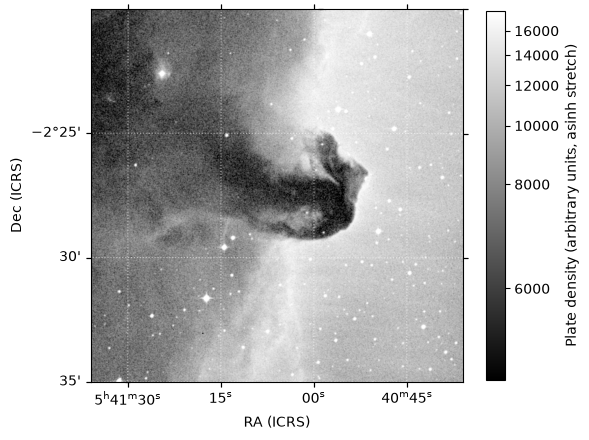

In [34]:
# percent=99.5 clips the brightest 0.5% of pixels, which is why the stars saturate
norm = simple_norm(image, stretch="asinh", percent=99.5)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection=wcs)
im = ax.imshow(image, origin="lower", cmap="gray", norm=norm)
ax.coords.grid(color="white", alpha=0.5, ls=":")
ax.set_xlabel("RA (ICRS)")
ax.set_ylabel("Dec (ICRS)")
fig.colorbar(im, ax=ax, label="Plate density (arbitrary units, asinh stretch)", shrink=0.8)
plt.show()

### Better: WCS axes, `origin='lower'`, asinh stretch, greyscale

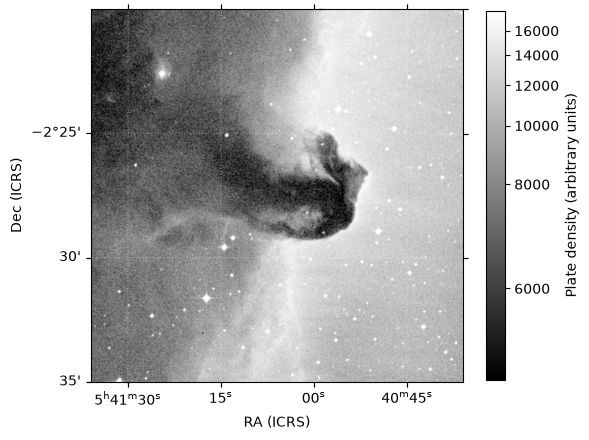

In [35]:
norm = simple_norm(image, stretch="asinh", percent=99.5)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection=wcs)
im = ax.imshow(image, origin="lower", cmap="gray", norm=norm)
ax.coords.grid(color="white", alpha=0.3, ls=":")
ax.set_xlabel("RA (ICRS)")
ax.set_ylabel("Dec (ICRS)")
fig.colorbar(im, ax=ax, label="Plate density (arbitrary units)", shrink=0.8)
plt.show()

---
# 8. Sky map (Haslam 408 MHz)

The Haslam all-sky map at 408 MHz (destriped version, Remazeilles et al. 2015, from [LAMBDA](https://lambda.gsfc.nasa.gov/product/foreground/fg_2014_haslam_408_info.html), at NSIDE 256): radio emission, mostly Galactic synchrotron, as brightness temperature in K.

In [36]:
sky = hp.read_map("data/haslam_nside256.fits")              # Haslam 408 MHz, brightness temperature in K, Galactic coordinates

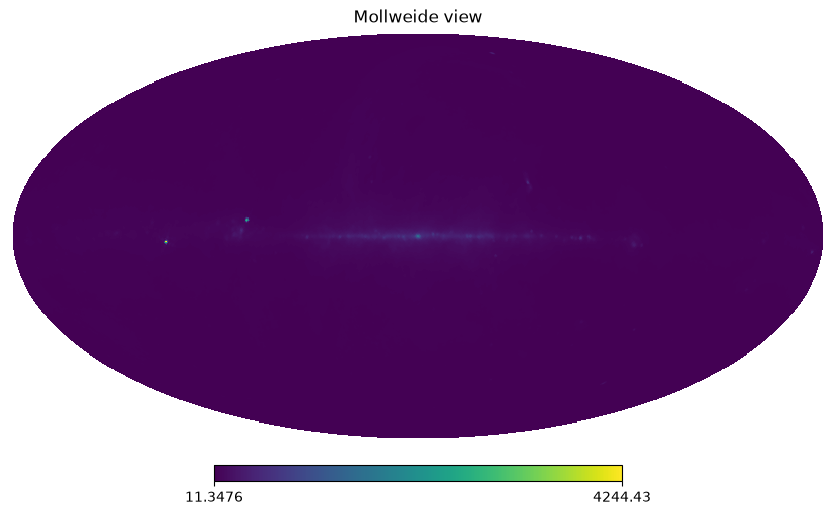

In [37]:
hp.mollview(sky)

**Ask the room:** what is this map showing you? What would you change?

<details>
<summary>Presenter notes</summary>

- Linear colour scale: the Galactic plane (up to ~4000 K) sets the range, so the rest of the sky (10–50 K) is a single colour. The North Polar Spur and the other loops are invisible.
- No title and no units on the colour bar (brightness temperature in K, at 408 MHz).
- Which coordinate system is this? Galactic, but nothing says.
- The sky is positive with a huge dynamic range: use a sequential colour map, and a log scale (or a clip that you state).

</details>

### Better: sequential colour map, clipped linear scale, units, title

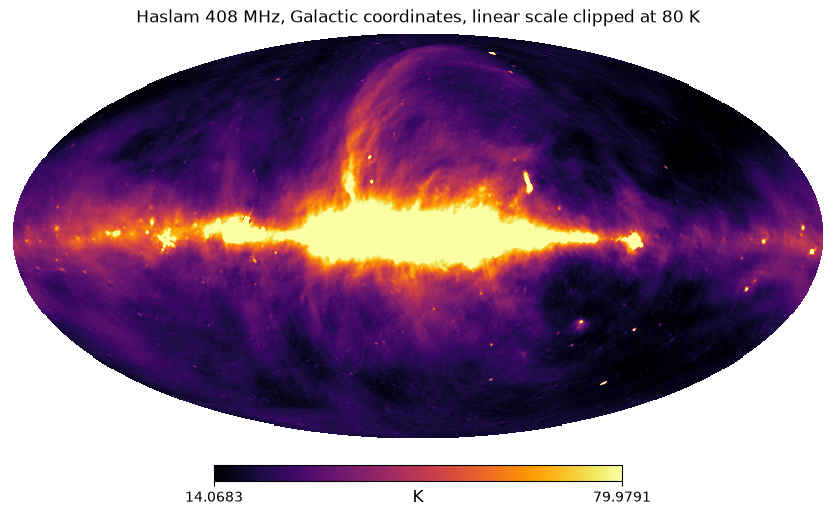

In [38]:
lo, hi = np.percentile(sky, [1, 95])               # clip: the brightest 5% of pixels (the plane) saturate
hp.mollview(sky, cmap="inferno", min=lo, max=hi, unit="K",
            title=f"Haslam 408 MHz, Galactic coordinates, linear scale clipped at {hi:.0f} K")

### Best: log colour scale

The Galactic plane is a few hundred times brighter than the faintest sky, so a clipped linear scale saturates it. A log scale shows the plane and the faint loops and spurs at once. The trade-off is that the colour bar is no longer linear, so it must be labelled in real units and say so.

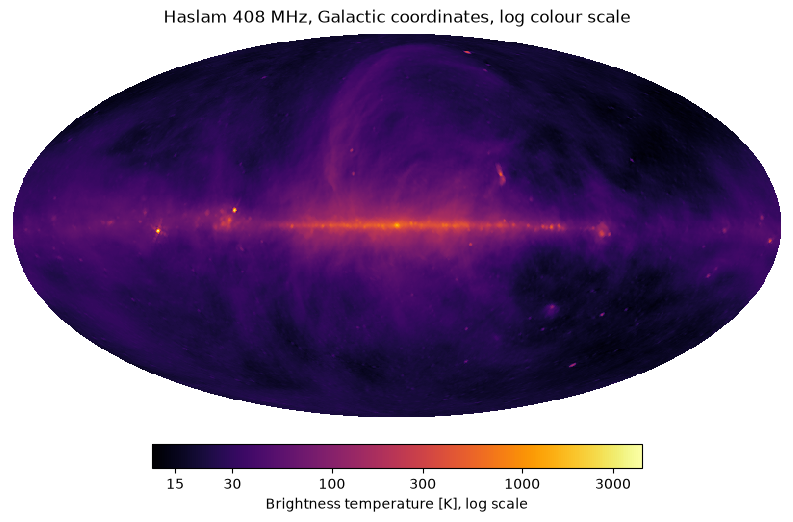

In [39]:
hp.mollview(sky, norm="log", cmap="inferno", cbar=False,
            title="Haslam 408 MHz, Galactic coordinates, log colour scale")
ticks_K = [15, 30, 100, 300, 1000, 3000]
cb = plt.colorbar(plt.gca().get_images()[0], orientation="horizontal", shrink=0.6, pad=0.05, ticks=ticks_K)
cb.set_ticklabels([f"{t:g}" for t in ticks_K])
cb.set_label("Brightness temperature [K], log scale")

---
# 9. Forest plots

Measurements of $H_0$ from different methods. Values are approximate and only for illustration.

In [40]:
labels = ["Planck CMB", "ACT CMB", "SPT-3G CMB", "BAO + BBN",
          "SH0ES Cepheids", "CCHP TRGB", "H0LiCOW lenses", "Megamasers", "SBF"]
H0 = np.array([67.4, 67.9, 68.8, 67.6, 73.0, 69.8, 73.3, 73.9, 73.3])
H0_err = np.array([0.5, 1.5, 1.5, 1.1, 1.0, 1.7, 1.8, 3.0, 2.5])
early = np.array([True, True, True, True, False, False, False, False, False])

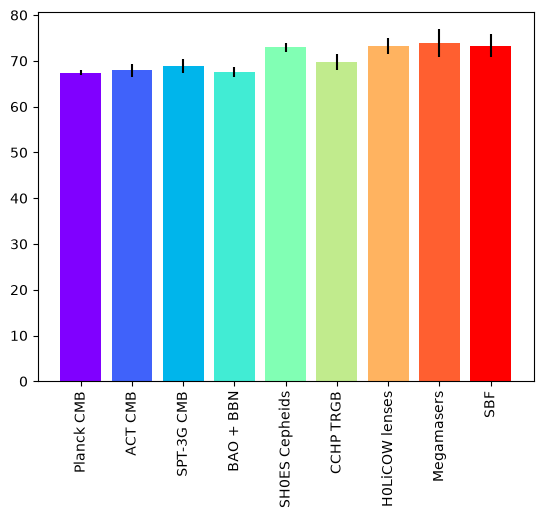

In [41]:
plt.bar(labels, H0, yerr=H0_err, color=plt.cm.rainbow(np.linspace(0, 1, len(H0))))
plt.xticks(rotation=90)
plt.show()

**Ask the room:** is there a tension? How big is it?

<details>
<summary>Presenter notes</summary>

- Bars start at zero, so a 5 km/s/Mpc difference looks like nothing. A bar's length means "amount", which isn't the point here: the point is where each value sits, with its error.
- Rotated labels are hard to read. Turn the plot sideways so the labels sit horizontally.
- The rainbow colours mean nothing. Use colour to show something, e.g. early- vs late-Universe probes.
- No axis label or units.
- The order is arbitrary. Group the methods.

</details>

### Better: horizontal forest plot, grouped, with units

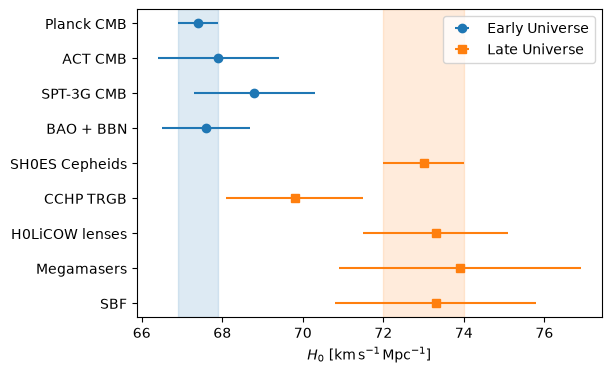

In [42]:
y = np.arange(len(H0))[::-1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(H0[early], y[early], xerr=H0_err[early], fmt="o", color="C0", label="Early Universe")
ax.errorbar(H0[~early], y[~early], xerr=H0_err[~early], fmt="s", color="C1", label="Late Universe")
ax.axvspan(67.4 - 0.5, 67.4 + 0.5, color="C0", alpha=0.15)
ax.axvspan(73.0 - 1.0, 73.0 + 1.0, color="C1", alpha=0.15)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel(r"$H_0\ [\mathrm{km\,s^{-1}\,Mpc^{-1}}]$")
ax.legend(loc="upper right")
plt.show()

---
# 10. Time for a makeover

One synthetic figure, restyled four ways: colour, custom palettes, text, and a style file. The section runs on its own: start with the setup cell below.

In [43]:
# Setup for this section: runs on its own, no data from earlier sections
import shutil
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

plt.style.use("default")                     # start from Matplotlib's defaults

# Synthetic delay power spectrum P(tau), seeded so everyone sees the same figure
rng_mk = np.random.default_rng(2024)
tau = np.linspace(-3000, 3000, 41)           # delay [ns]
P_true = 5e-2 * np.exp(-np.abs(tau) / 250) + 8e-4
P_noise = np.full_like(tau, 2e-4)
cases = {
    "Case I": P_true * (1 + 0.1 * rng_mk.normal(size=tau.size)),
    "Case II": (P_true + 4e-3 * np.exp(-np.abs(tau) / 1500)) * (1 + 0.1 * rng_mk.normal(size=tau.size)),
    "Case III": 0.5 * P_true * (1 + 0.1 * rng_mk.normal(size=tau.size)),
}
offsets = {"Case I": -40, "Case II": 0, "Case III": 40}   # ns, so the error bars don't sit on top of each other


def make_plot(colors=None, linestyles=None, markers=None, hatch="///", legend=True):
    """P(tau) for the three cases.

    Style-free: no colours, fonts, line widths or sizes are hard-coded. Anything not passed
    in comes from rcParams, so a style file changes the look without touching this code.
    """
    fig, ax = plt.subplots()
    handles = {}
    for i, (name, P) in enumerate(cases.items()):
        kw = {}
        if colors is not None:
            kw["color"] = colors[i]
        if linestyles is not None:
            kw["linestyle"] = linestyles[i]
        if markers is not None:
            kw["marker"] = markers[i]
        # one errorbar call per case: colour, linestyle and marker come from the property cycle
        cont = ax.errorbar(tau + offsets[name], P, yerr=0.15 * P, label=name, **kw)
        handles[name] = cont.lines[0]
    ref = mpl.rcParams["axes.edgecolor"]      # reference elements follow the style's axes colour
    ax.plot(tau, P_true, linestyle=":", marker="", color=ref, label="True")
    ax.plot(tau, P_noise, linestyle="-.", marker="", color=ref, label="Noise")
    ax.axvline(300, linestyle=":", color=ref)
    if hatch:
        ax.axvspan(0, 590, hatch=hatch, facecolor="none", edgecolor=ref, label="Excluded")
    else:
        ax.axvspan(0, 590, alpha=0.2, label="Excluded")
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1e-1)
    ax.set_xlim(-3100, 3100)
    ax.set_xlabel(r"$\tau$ [ns]")
    ax.set_ylabel(r"$P(\tau)$ [arb. units]")
    if legend:
        ax.legend()
    return fig, ax, handles

## Part 1: Colour schemes

Choose the palette type from the type of data, then check the figure still works in grayscale. Colour should never be the only thing that tells two lines apart.

| Your data | Palette type | Examples |
|---|---|---|
| Ordered, one direction (intensity, counts, density) | Sequential | `viridis`, `cividis`, `inferno`, `Blues` |
| Signed, with a meaningful zero (residuals, differences, correlations) | Diverging, centred on zero | `RdBu_r`, `coolwarm`, `PuOr`, with `vmin=-vmax` |
| Unordered categories (instruments, cases, surveys) | Qualitative | [Okabe-Ito](https://jfly.uni-koeln.de/color/), `tab10`, `Set2` |
| Many lines (more than about 6) | Don't rely on colour alone: sample a sequential map if the lines are ordered, otherwise vary linestyle and marker, split into panels, or highlight one and grey the rest | `viridis(np.linspace(0, 1, N))`, small multiples |

In [44]:
def grayscale_check(fig):
    """Show fig next to its grayscale version (luma = 0.299 R + 0.587 G + 0.114 B)."""
    fig.canvas.draw()
    rgb = np.asarray(fig.canvas.buffer_rgba())[..., :3]
    gray = rgb @ np.array([0.299, 0.587, 0.114])
    fig2, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(rgb)
    axes[0].set_title("Original")
    axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Grayscale")
    for a in axes:
        a.set_axis_off()
    plt.show()

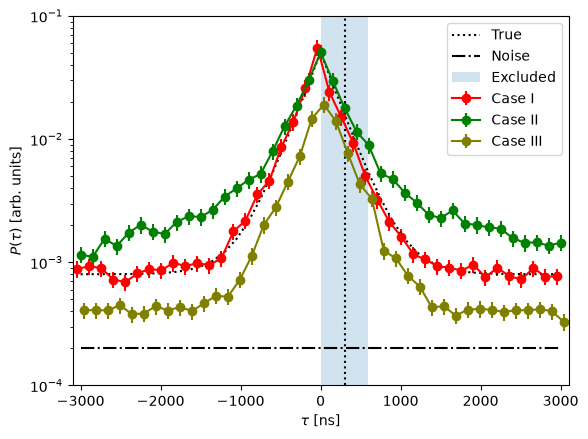

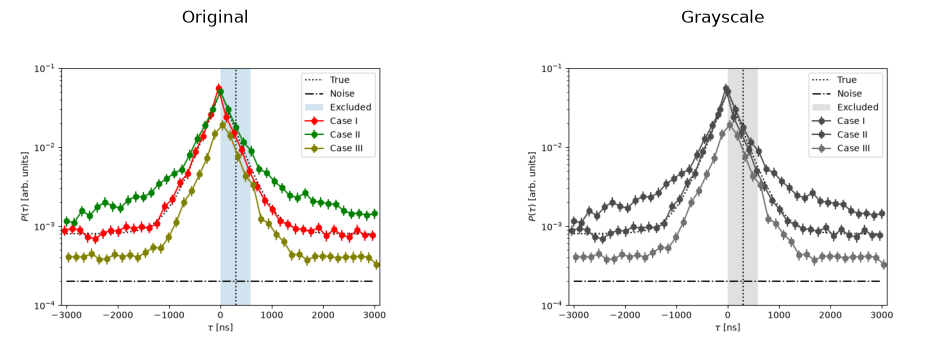

In [45]:
fig, ax, _ = make_plot(colors=["red", "green", "olive"], linestyles=["-", "-", "-"],
                       markers=["o", "o", "o"], hatch=None)
grayscale_check(fig)

**Improved:** [Okabe-Ito](https://jfly.uni-koeln.de/color/) colours, plus a different linestyle and marker for each case, and a hatched region instead of a tint. Every case can be told apart in grayscale too.

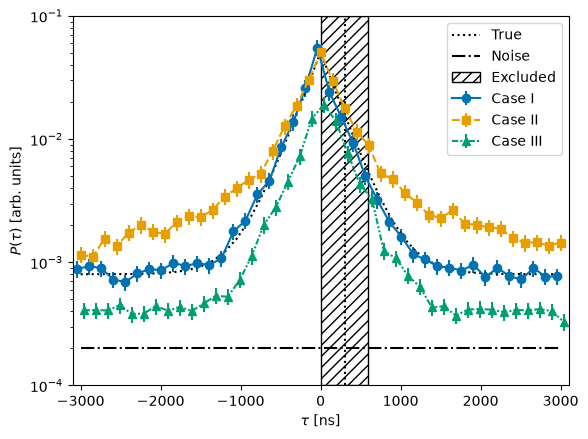

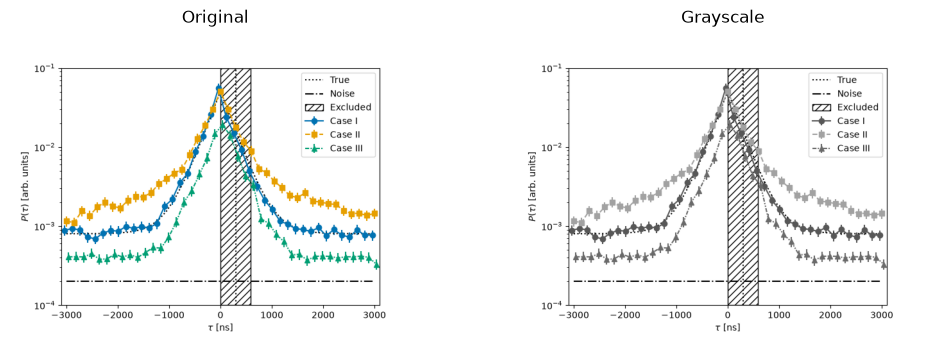

In [46]:
fig, ax, _ = make_plot(colors=["#0072B2", "#E69F00", "#009E73"],
                       linestyles=["-", "--", (0, (3, 1, 1, 1, 1, 1))],
                       markers=["o", "s", "^"],
                       hatch="///")
grayscale_check(fig)

**Stretch goal.** Screenshot your improved figure and the red/green/olive one, and look at both in a colour-vision simulator (the [Colorblindly](https://chromewebstore.google.com/detail/colorblindly/floniaahmccleoclneebhhmnjgdfijgg) browser extension; try deuteranopia and protanopia). Which cases merge in the bad version?

**Resources**
- [ColorBrewer](https://colorbrewer2.org/)
- [Matplotlib colormaps reference](https://matplotlib.org/stable/users/explain/colors/colormaps.html)
- [Colorblindly](https://chromewebstore.google.com/detail/colorblindly/floniaahmccleoclneebhhmnjgdfijgg) (browser extension)

## Part 2: Custom palettes

A colormap is a list of colours interpolated in order, so you can build your own from hex codes. Check that its lightness rises steadily; otherwise the image shows features that are not in the data.

In [47]:
# A small synthetic image: two Gaussian blobs plus a little noise
yy, xx = np.mgrid[-1:1:150j, -1:1:150j]
img = (np.exp(-((xx + 0.35) ** 2 + (yy + 0.2) ** 2) / 0.05)
       + 0.6 * np.exp(-((xx - 0.4) ** 2 + (yy - 0.3) ** 2) / 0.02)
       + 0.03 * np.random.default_rng(7).normal(size=xx.shape))

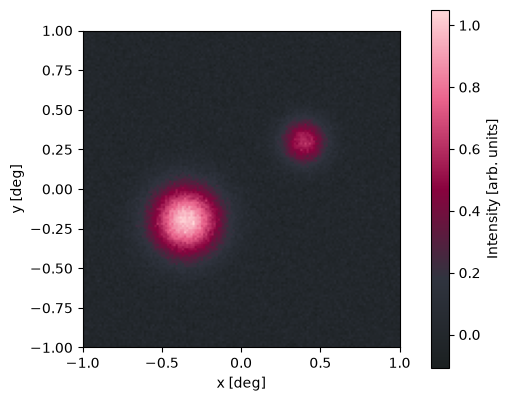

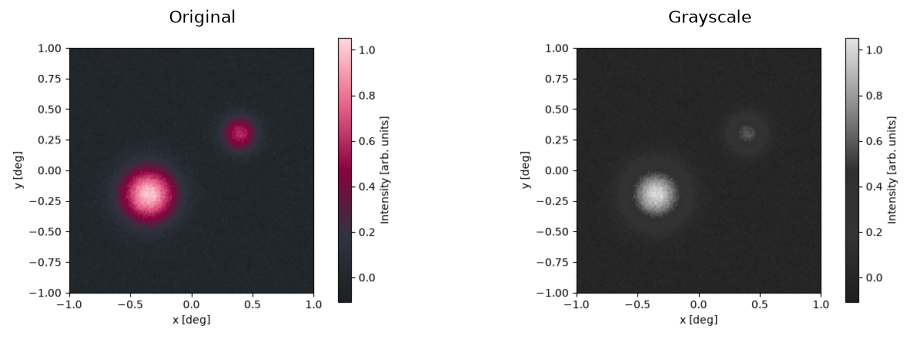

In [48]:
makeover = LinearSegmentedColormap.from_list(
    "makeover", ["#1B2021", "#30343F", "#89023E", "#EA638C", "#FFD9DA"])

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
im = ax.imshow(img, cmap=makeover, origin="lower", extent=[-1, 1, -1, 1])
fig.colorbar(im, ax=ax, label="Intensity [arb. units]")
ax.set_xlabel("x [deg]")
ax.set_ylabel("y [deg]")
grayscale_check(fig)

**Lightness check.** The second and third stops (`#30343F`, `#89023E`) have almost the same lightness (luma about 52 and 49 out of 255; it even dips slightly). So the crimson that marks mid-range values is barely lighter than the background, and in grayscale the smaller blob, which peaks at 0.6, almost disappears. A pretty palette is not automatically a good colormap.

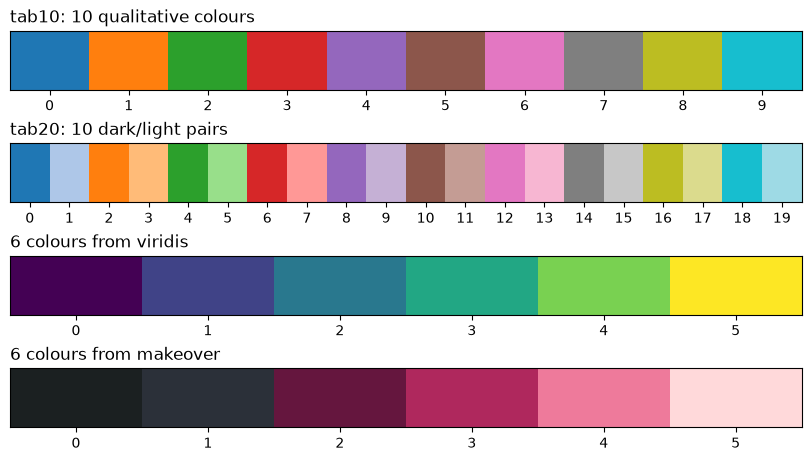

In [49]:
def strip(ax, colors, title):
    ax.imshow(mpl.colors.to_rgba_array(colors)[None, :, :], aspect="auto")
    ax.set_yticks([])
    ax.set_xticks(range(len(colors)))
    ax.set_title(title, loc="left")

N = 6
fig, axes = plt.subplots(4, 1, figsize=(8, 4.5), layout="constrained")
strip(axes[0], plt.colormaps["tab10"].colors, "tab10: 10 qualitative colours")
strip(axes[1], plt.colormaps["tab20"].colors, "tab20: 10 dark/light pairs")
# N evenly spaced colours from any colormap: call it on np.linspace(0, 1, N)
strip(axes[2], plt.colormaps["viridis"](np.linspace(0, 1, N)), f"{N} colours from viridis")
strip(axes[3], makeover(np.linspace(0, 1, N)), f"{N} colours from makeover")
plt.show()

In [50]:
# Optional colormap libraries: none is required, and nothing here fails if they are missing
import importlib

examples = {
    "cmasher": 'import cmasher; ax.imshow(img, cmap="cmr.rainforest")',
    "cmocean": 'import cmocean; ax.imshow(img, cmap="cmo.thermal")',
    "colorcet": 'import colorcet; ax.imshow(img, cmap="cet_fire")',
    "cmcrameri": 'import cmcrameri; ax.imshow(img, cmap="cmc.batlow")',
}
for name, example in examples.items():
    try:
        importlib.import_module(name)
        print(f"{name:10s} installed, e.g.  {example}")
    except Exception:
        print(f"{name:10s} not installed: pip install {name}")

cmasher    not installed: pip install cmasher
cmocean    not installed: pip install cmocean
colorcet   not installed: pip install colorcet
cmcrameri  not installed: pip install cmcrameri


**Solution:** a palette ordered dark to light, so lightness rises steadily.

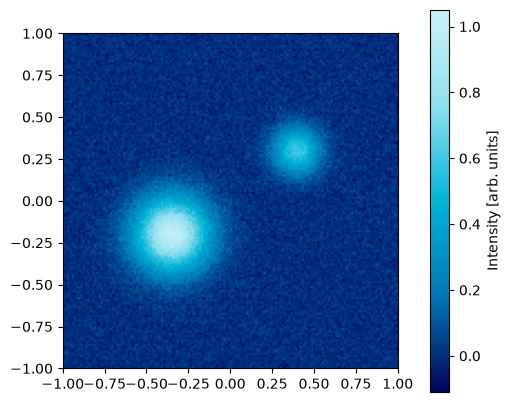

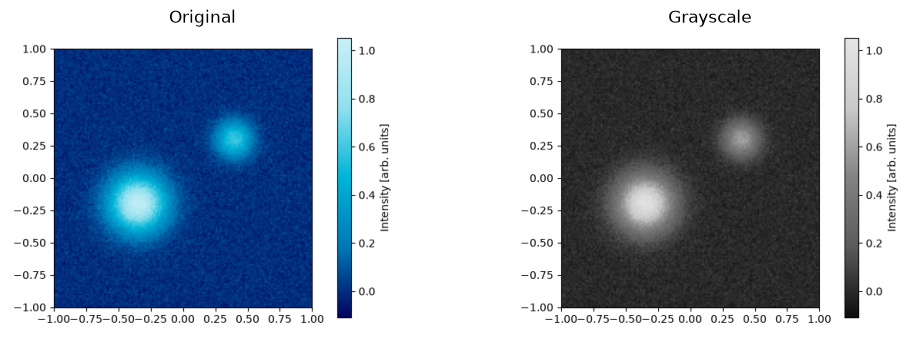

In [51]:
mine = LinearSegmentedColormap.from_list("mine", ["#03045E", "#0077B6", "#00B4D8", "#90E0EF", "#CAF0F8"])

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
im = ax.imshow(img, cmap=mine, origin="lower", extent=[-1, 1, -1, 1])
fig.colorbar(im, ax=ax, label="Intensity [arb. units]")
grayscale_check(fig)

**A gradient is for continuous data, not for separate line colours.** Neighbouring samples of a gradient look alike, and nobody can match a line to "the fourth shade of pink". For separate lines use a qualitative palette. Sample a gradient only when the lines themselves are ordered (redshift bins, frequencies, time).

**Stretch goal.** Register your map with `mpl.colormaps.register(mine)` so `cmap="mine"` works by name, and try `mine.reversed()`. Or build a diverging map (dark, light, dark, with the light colour in the middle) and show `img - img.mean()` with `vmin=-vmax`.

**Resources**
- [Gradient generator](https://eltos.github.io/gradient/)
- [Coolors](https://coolors.co/)
- [CMasher](https://cmasher.readthedocs.io/)
- [cmocean](https://matplotlib.org/cmocean/)
- [colorcet](https://colorcet.holoviz.org/)

## Part 3: Text

Label the data where it is, instead of in a legend the reader has to decode. Set font sizes once with rcParams, not in every call.

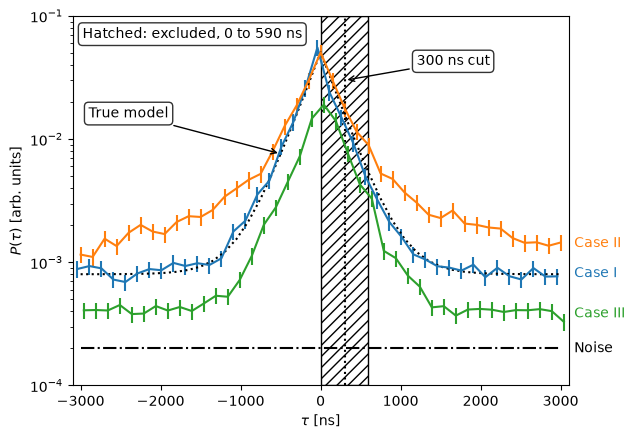

In [52]:
fig, ax, h = make_plot(legend=False)
ref = mpl.rcParams["axes.edgecolor"]
box = dict(boxstyle="round", facecolor=mpl.rcParams["axes.facecolor"], alpha=0.8)   # keeps text readable over lines

# Direct labels at the right edge, at each line's last value. x is in axes fraction, y in data units
for name, line in h.items():
    ax.annotate(name, xy=(1, cases[name][-3:].mean()), xycoords=("axes fraction", "data"),
                xytext=(4, 0), textcoords="offset points", va="center", color=line.get_color())
ax.annotate("Noise", xy=(1, P_noise[-1]), xycoords=("axes fraction", "data"),
            xytext=(4, 0), textcoords="offset points", va="center", color=ref)

# Text in axes coordinates: (0, 0) is bottom left and (1, 1) top right, whatever the data
ax.text(0.02, 0.97, "Hatched: excluded, 0 to 590 ns", transform=ax.transAxes, va="top", bbox=box)

# Annotations with arrows, in data coordinates
ax.annotate("True model", xy=(-500, 7.6e-3), xytext=(-2900, 1.5e-2),
            arrowprops=dict(arrowstyle="->"), bbox=box)
ax.annotate("300 ns cut", xy=(300, 3e-2), xytext=(1200, 4e-2),
            arrowprops=dict(arrowstyle="->"), bbox=box)
plt.show()

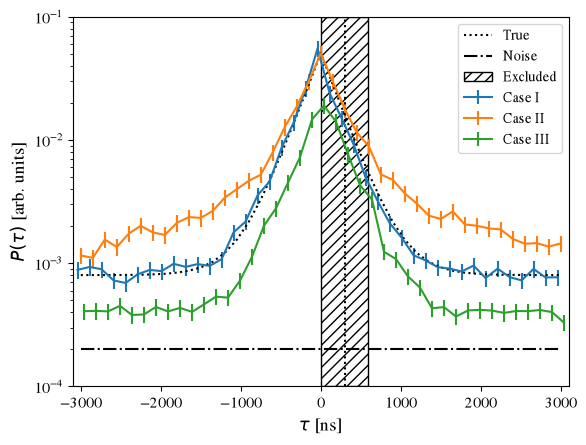

In [53]:
# Set fonts once for every figure that follows
plt.rcParams.update({
    "font.family": "STIXGeneral",   # a Times-like serif that ships with Matplotlib
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
})
fig, ax, _ = make_plot()
plt.show()

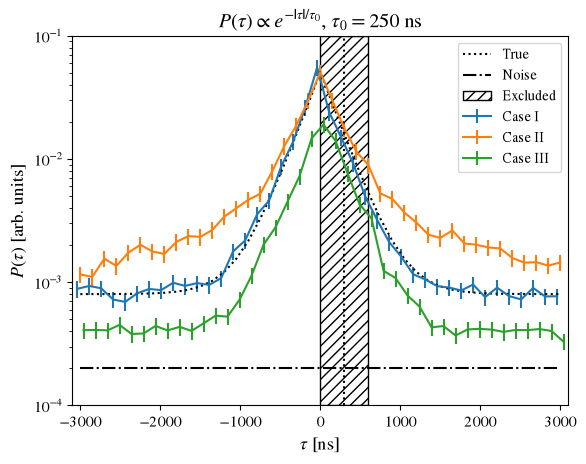

In [54]:
# Mathtext: Matplotlib's own TeX-like renderer, no LaTeX install needed.
# "stix" makes the maths match the STIX text font set above.
plt.rcParams["mathtext.fontset"] = "stix"

fig, ax, _ = make_plot()
ax.set_ylabel(r"$P(\tau)$ [arb. units]")     # anything between $...$ is typeset as maths
ax.set_title(r"$P(\tau) \propto e^{-|\tau|/\tau_0}$, $\tau_0 = 250$ ns")
plt.show()

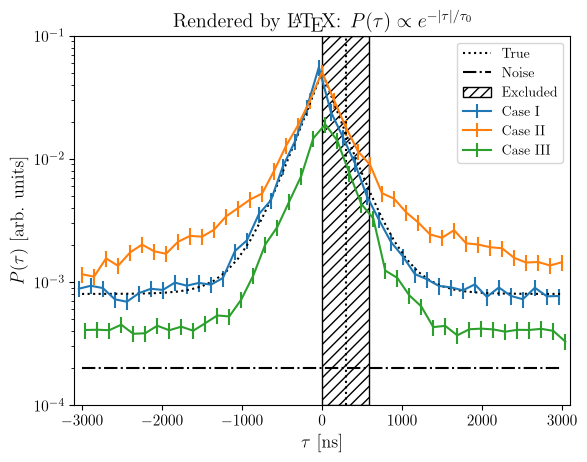

In [55]:
# Real LaTeX, only if it is installed. Otherwise mathtext (above) is already very close.
if shutil.which("latex"):
    try:
        with plt.rc_context({"text.usetex": True, "font.family": "serif"}):
            fig, ax, _ = make_plot()
            ax.set_title(r"Rendered by \LaTeX: $P(\tau) \propto e^{-|\tau|/\tau_0}$")
            fig.canvas.draw()         # render now, so a broken LaTeX install is caught here
        plt.show()
    except Exception as err:
        plt.close("all")
        print(f"LaTeX found but it failed ({type(err).__name__}), using mathtext")
else:
    print("LaTeX not found, using mathtext")

**Solution:** font sizes set once, and Case II labelled on the plot.

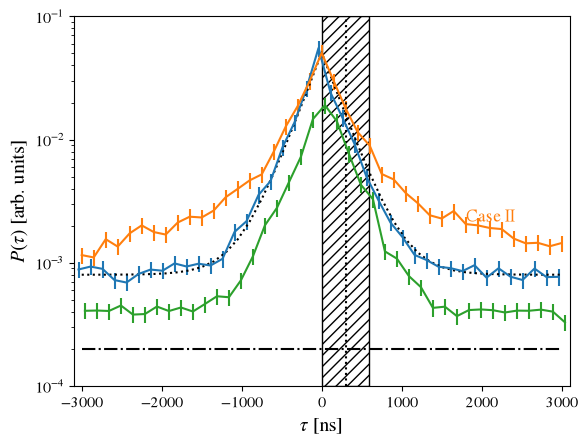

In [56]:
plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})
fig, ax, h = make_plot(legend=False)
ax.text(1800, 2e-3, "Case II", color=h["Case II"].get_color(), va="bottom")
plt.show()

**Stretch goal.** Give each direct label a short leader line with `arrowprops=dict(arrowstyle="-")`. Add a secondary x-axis with `ax.secondary_xaxis("top", functions=(f, f_inv))`, e.g. $\tau$ in µs.

**Resources**
- [Matplotlib: text in figures](https://matplotlib.org/stable/users/explain/text/text_intro.html)
- [Matplotlib: mathtext](https://matplotlib.org/stable/users/explain/text/mathtext.html)
- [Matplotlib: text rendering with LaTeX (usetex)](https://matplotlib.org/stable/users/explain/text/usetex.html)

## Part 4: The style file

Put the choices from Parts 1 to 3 into one `.mplstyle` file, and every figure picks them up. `make_plot()` hard-codes nothing, so the same call gets a new look.

The style file, filled in. Format: `key: value`, one per line, no quotes around values, and hex colours **without** the `#` (in a style file `#` starts a comment).

In [57]:
%%writefile makeover.mplstyle
# makeover.mplstyle   format:  key: value   (no quotes; hex colours WITHOUT the #, because # starts a comment)

# Text
font.size: 12               # base font size in points
axes.labelsize: large           # axis labels one step bigger than font.size
axes.titlesize: large           # titles too

# Lines, markers, hatching
lines.linewidth: 2             # data line width in points
lines.markersize: 5             # marker size in points
hatch.linewidth: 0.5           # hatch stroke width in points, thinner than the data lines
axes.edgecolor: 444444          # axes frame colour; make_plot also uses it for True, Noise and the hatch

# Colour AND line texture: case i gets colour i, linestyle i and marker i (Okabe-Ito colours)
axes.prop_cycle: cycler(color=['0072B2', 'E69F00', '009E73']) + cycler(linestyle=['-', '--', (0, (3, 1, 1, 1, 1, 1))]) + cycler(marker=['o', 's', '^'])

# Ticks
xtick.direction: in           # in or out
ytick.direction: in             # same as xtick.direction
xtick.top: True                 # ticks on all four sides
ytick.right: True

# Legend
legend.frameon: False            # True or False: no box around the legend

Overwriting makeover.mplstyle


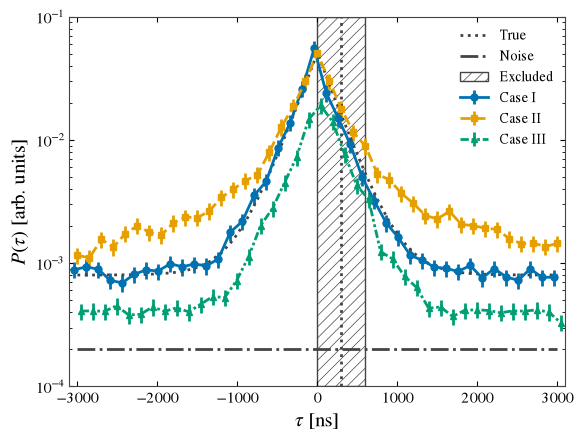

In [58]:
plt.style.use("makeover.mplstyle")
fig, ax, _ = make_plot()          # exactly the same call as in Part 1, no arguments
plt.show()

Styles **layer**: `plt.style.use` only changes the keys in the file, so the STIX fonts from Part 3 are still active above. Start from `"default"` to get only what the file says.

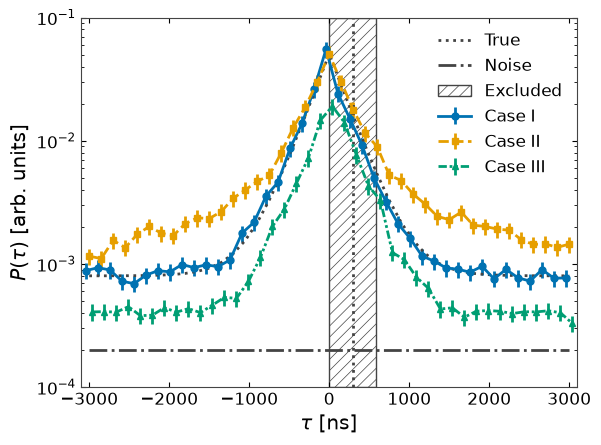

In [59]:
plt.style.use(["default", "makeover.mplstyle"])
fig, ax, _ = make_plot()
plt.show()

A second, small style can sit on top. `talk.mplstyle` only makes things bigger for slides; later styles win where they overlap.

In [60]:
%%writefile talk.mplstyle
# talk.mplstyle: bigger everything for slides. Layer it on top of another style.
font.size: 16
lines.linewidth: 3
lines.markersize: 8
figure.figsize: 8, 5.5

Overwriting talk.mplstyle


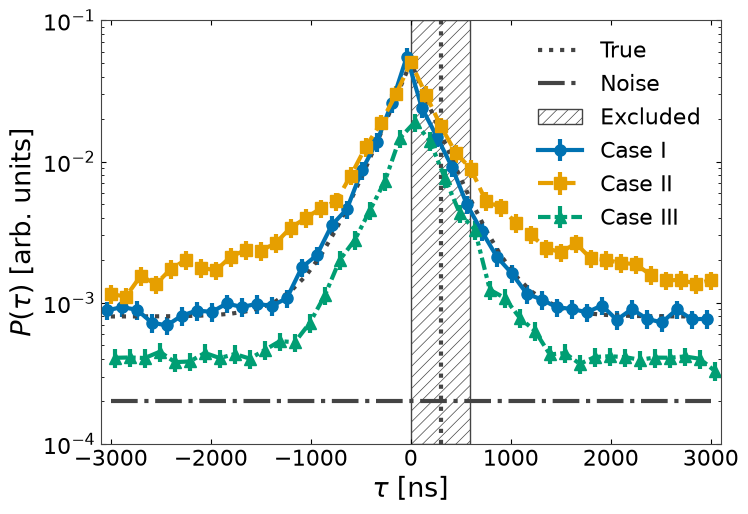

In [61]:
plt.style.use(["makeover.mplstyle", "talk.mplstyle"])
fig, ax, _ = make_plot()
plt.show()

In [62]:
# Built-in styles: try plt.style.use(["default", "ggplot"]) and re-run make_plot()
print(plt.style.available)

['Solarize_Light2', 'arviz-bluish', 'arviz-brownish', 'arviz-colors', 'arviz-cyanish', 'arviz-darkgrid', 'arviz-doc', 'arviz-docgrid', 'arviz-grayscale', 'arviz-greenish', 'arviz-orangish', 'arviz-plasmish', 'arviz-purplish', 'arviz-redish', 'arviz-royish', 'arviz-viridish', 'arviz-white', 'arviz-whitegrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


**Don't hard-code colours or fonts in plotting functions.** `make_plot` only says *what* to draw (the data, the labels, which line is the reference). The style decides *how* it looks, so one file restyles every figure in a paper or a talk. Pass a colour in only when it carries meaning, and let reference elements borrow from rcParams (here `axes.edgecolor`).

In [63]:
plt.style.use("default")          # back to Matplotlib's defaults for the rest of the notebook

**Stretch goal.** Add `savefig.dpi: 300`, `savefig.bbox: tight`, and `axes.grid: True` with `grid.alpha: 0.3`. Then make `paper.mplstyle` with `figure.figsize: 3.4, 2.6` (one journal column) and layer it instead of `talk`. Copy your style into `mpl.get_configdir() + "/stylelib/"` so `plt.style.use("makeover")` works from any folder.

**Resources**
- [Matplotlib: style sheets and rcParams](https://matplotlib.org/stable/users/explain/customizing.html)

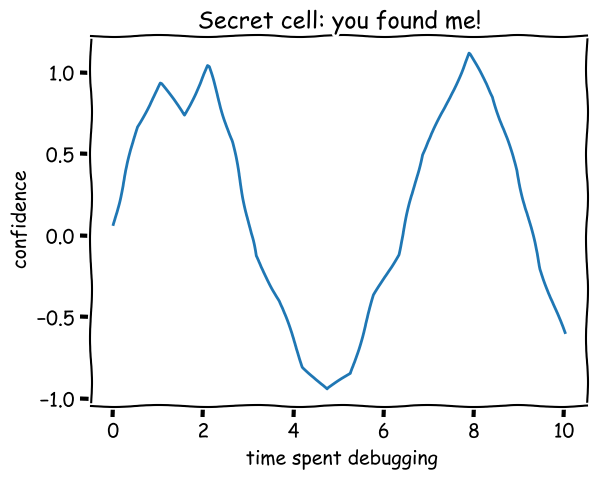

In [64]:
import logging
import numpy as np
import matplotlib.pyplot as plt

# Silence the harmless "font not found" warnings
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

rng = np.random.default_rng(1)
xs = np.linspace(0, 10, 20)
ys = np.sin(xs) + 0.2 * rng.normal(size=xs.size)

with plt.xkcd():
    fig, ax = plt.subplots()
    ax.plot(xs, ys)
    ax.set_title("Secret cell: you found me!")
    ax.set_xlabel("time spent debugging")
    ax.set_ylabel("confidence")
plt.show()

## Appendix: options gallery

Every cell below is independent: it imports what it needs and makes its own seeded data, so you can copy any one of them out on its own.
It mirrors the cheat sheet appendix (sections A to D).

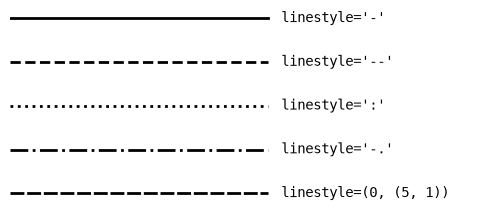

In [65]:
# Linestyles: each line labelled with the code that draws it
import numpy as np
import matplotlib.pyplot as plt

with plt.style.context("default"):
    styles = ["-", "--", ":", "-.", (0, (5, 1))]
    fig, ax = plt.subplots(figsize=(6, 2.5))
    for i, ls in enumerate(styles):
        ax.plot([0, 1], [i, i], linestyle=ls, color="k", lw=2)
        ax.text(1.05, i, f"linestyle={ls!r}", va="center", family="monospace")
    ax.set_xlim(0, 1.8)
    ax.invert_yaxis()
    ax.set_axis_off()
    plt.show()

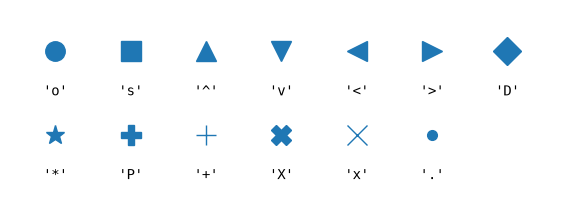

In [66]:
# Markers: a labelled grid of marker codes
import numpy as np
import matplotlib.pyplot as plt

with plt.style.context("default"):
    markers = ["o", "s", "^", "v", "<", ">", "D", "*", "P", "+", "X", "x", "."]
    fig, ax = plt.subplots(figsize=(7, 2.5))
    for i, m in enumerate(markers):
        x, y = i % 7, -(i // 7)
        ax.plot(x, y, marker=m, ms=14, ls="none", color="C0")
        ax.text(x, y - 0.4, repr(m), ha="center", va="top", family="monospace")
    ax.set_xlim(-0.6, 6.6)
    ax.set_ylim(-1.8, 0.5)
    ax.set_axis_off()
    plt.show()

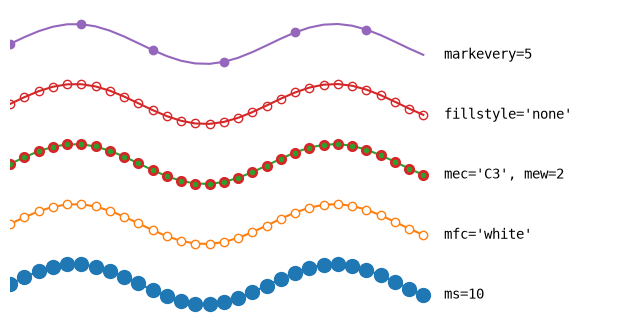

In [67]:
# Marker options: size, face colour, edge colour, hollow markers, and markevery
import numpy as np
import matplotlib.pyplot as plt

with plt.style.context("default"):
    x = np.linspace(0, 10, 30)
    options = [dict(ms=10), dict(mfc="white"), dict(mec="C3", mew=2),
               dict(fillstyle="none"), dict(markevery=5)]
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, kw in enumerate(options):
        y = np.sin(x) + 3 * i
        ax.plot(x, y, "o-", color=f"C{i}", **kw)
        label = ", ".join(f"{k}={v!r}" for k, v in kw.items())
        ax.text(10.5, y[-1], label, va="center", family="monospace")
    ax.set_xlim(0, 15)
    ax.set_axis_off()
    plt.show()

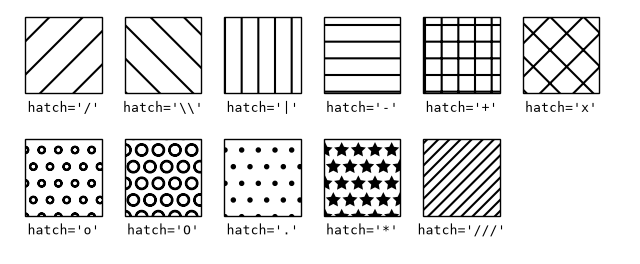

In [68]:
# Hatches: hollow rectangles with each hatch pattern (hatch.linewidth sets the stroke width)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

with plt.style.context("default"), plt.rc_context({"hatch.linewidth": 1.5}):
    hatches = ["/", "\\", "|", "-", "+", "x", "o", "O", ".", "*", "///"]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    for i, h in enumerate(hatches):
        x, y = 1.3 * (i % 6), -1.6 * (i // 6)
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none", edgecolor="k", hatch=h))
        ax.text(x + 0.5, y - 0.1, f"hatch={h!r}", ha="center", va="top", family="monospace", fontsize=9)
    ax.set_xlim(-0.2, 7.9)
    ax.set_ylim(-2.1, 1.1)
    ax.set_aspect("equal")
    ax.set_axis_off()
    plt.show()

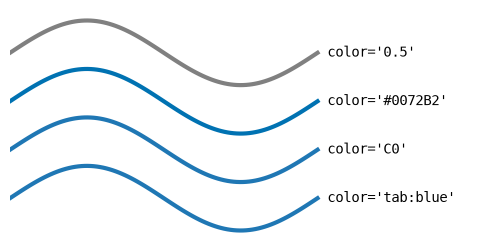

In [69]:
# Colour formats: a named colour, a cycle colour, a hex code and a grayscale string
import numpy as np
import matplotlib.pyplot as plt

with plt.style.context("default"):
    x = np.linspace(0, 2 * np.pi, 100)
    colors = ["tab:blue", "C0", "#0072B2", "0.5"]
    fig, ax = plt.subplots(figsize=(6, 3))
    for i, c in enumerate(colors):
        ax.plot(x, np.sin(x) + 1.5 * i, color=c, lw=3)
        ax.text(2 * np.pi + 0.2, 1.5 * i, f"color={c!r}", va="center", family="monospace")
    ax.set_xlim(0, 9.5)
    ax.set_axis_off()
    plt.show()

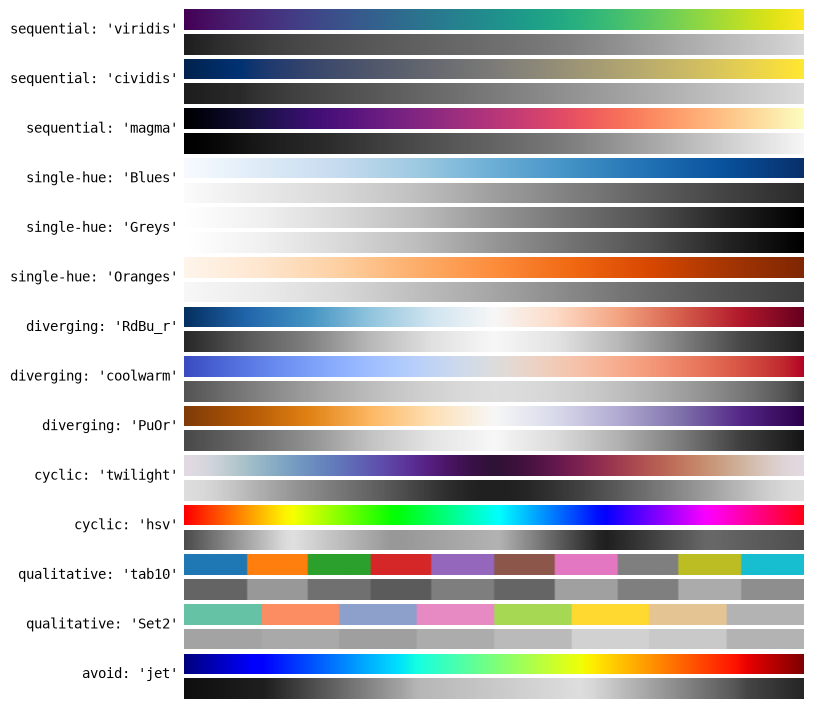

In [70]:
# Colormap gallery: each colormap as a strip, with its grayscale (lightness) version underneath
import numpy as np
import matplotlib.pyplot as plt

groups = {"sequential": ["viridis", "cividis", "magma"],
          "single-hue": ["Blues", "Greys", "Oranges"],
          "diverging": ["RdBu_r", "coolwarm", "PuOr"],
          "cyclic": ["twilight", "hsv"],
          "qualitative": ["tab10", "Set2"],
          "avoid": ["jet"]}
with plt.style.context("default"):
    names = [(kind, n) for kind, ns in groups.items() for n in ns]
    fig, axes = plt.subplots(2 * len(names), 1, figsize=(8, 0.32 * 2 * len(names)))
    grad = np.linspace(0, 1, 256)
    for k, (kind, name) in enumerate(names):
        rgb = plt.colormaps[name](grad)[:, :3]
        luma = rgb @ np.array([0.299, 0.587, 0.114])
        axes[2 * k].imshow(grad[None, :], cmap=name, aspect="auto")
        axes[2 * k + 1].imshow(luma[None, :], cmap="gray", vmin=0, vmax=1, aspect="auto")
        axes[2 * k].text(-0.01, 0, f"{kind}: {name!r}", transform=axes[2 * k].transAxes,
                         ha="right", va="center", family="monospace")
    for ax in axes:
        ax.set_axis_off()
    plt.show()

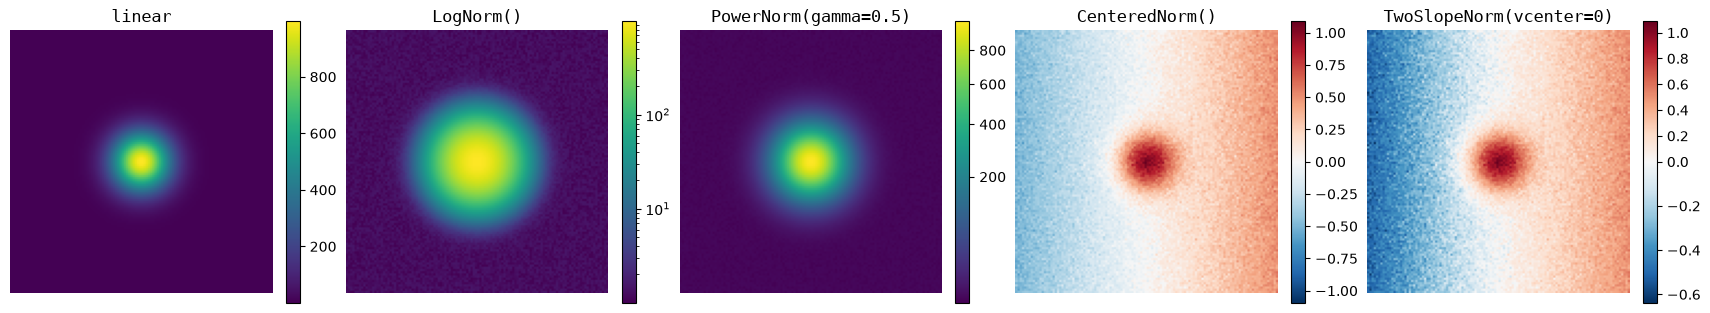

In [71]:
# Norms: the same kind of image under five colour normalisations
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, PowerNorm, CenteredNorm, TwoSlopeNorm

rng = np.random.default_rng(0)
yy, xx = np.mgrid[-1:1:120j, -1:1:120j]
blob = np.exp(-(xx**2 + yy**2) / 0.05)
positive = 1000 * blob + 1 + rng.uniform(0, 0.5, xx.shape)    # > 0, for LogNorm and PowerNorm
signed = blob + 0.5 * xx + 0.05 * rng.normal(size=xx.shape)     # crosses zero, for the centred norms
panels = [("linear", positive, None, "viridis"),
          ("LogNorm()", positive, LogNorm(), "viridis"),
          ("PowerNorm(gamma=0.5)", positive, PowerNorm(gamma=0.5), "viridis"),
          ("CenteredNorm()", signed, CenteredNorm(), "RdBu_r"),
          ("TwoSlopeNorm(vcenter=0)", signed, TwoSlopeNorm(vcenter=0), "RdBu_r")]
with plt.style.context("default"):
    fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), layout="constrained")
    for ax, (title, img, norm, cmap) in zip(axes, panels):
        im = ax.imshow(img, origin="lower", norm=norm, cmap=cmap)
        ax.set_title(title, family="monospace")
        ax.set_axis_off()
        fig.colorbar(im, ax=ax, shrink=0.85)
    plt.show()

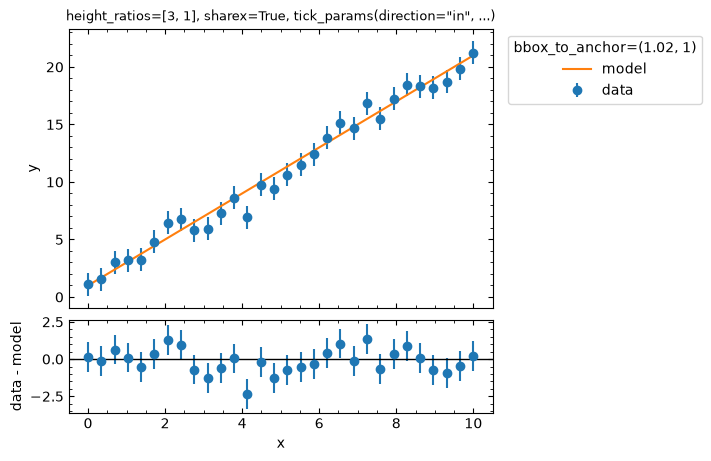

In [72]:
# Layout: main panel plus residual panel, legend outside the axes, ticks inside on all four sides
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = np.linspace(0, 10, 30)
model = 2 * x + 1
y = model + rng.normal(0, 1, x.size)
with plt.style.context("default"):
    fig, (ax, axr) = plt.subplots(2, 1, sharex=True, figsize=(7, 4.5), layout="constrained",
                                  gridspec_kw={"height_ratios": [3, 1]})
    ax.errorbar(x, y, yerr=1, fmt="o", label="data")
    ax.plot(x, model, label="model")
    ax.set_ylabel("y")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), title='bbox_to_anchor=(1.02, 1)')
    axr.errorbar(x, y - model, yerr=1, fmt="o")
    axr.axhline(0, color="k", lw=1)
    axr.set_xlabel("x")
    axr.set_ylabel("data - model")
    for a in (ax, axr):
        a.minorticks_on()
        a.tick_params(direction="in", top=True, right=True, which="both")
    ax.set_title('height_ratios=[3, 1], sharex=True, tick_params(direction="in", ...)', fontsize=9)
    plt.show()

### Library tour: numpy

np.logspace(1, 3, 5): [  10.           31.6227766   100.          316.22776602 1000.        ]
np.meshgrid X:
 [[0 1 2]
 [0 1 2]] 
Y:
 [[0 0 0]
 [1 1 1]]


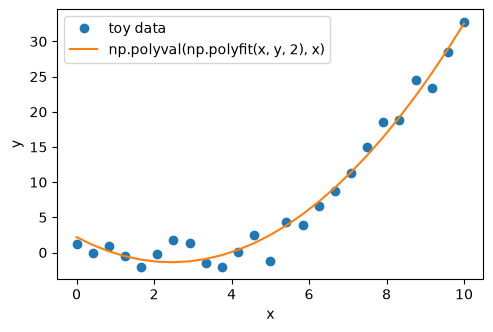

In [73]:
# numpy: linspace, logspace, meshgrid, and a polyfit/polyval fit to toy data
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = np.linspace(0, 10, 25)                          # 25 evenly spaced points
print("np.logspace(1, 3, 5):", np.logspace(1, 3, 5))  # evenly spaced in log10
X, Y = np.meshgrid(np.arange(3), np.arange(2))     # 2D coordinate grids
print("np.meshgrid X:\n", X, "\nY:\n", Y)
y = 0.5 * x**2 - 2 * x + 1 + rng.normal(0, 2, x.size)
coef = np.polyfit(x, y, 2)                          # least-squares quadratic
with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    ax.plot(x, y, "o", label="toy data")
    ax.plot(x, np.polyval(coef, x), label="np.polyval(np.polyfit(x, y, 2), x)")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    plt.show()

### Library tour: healpy

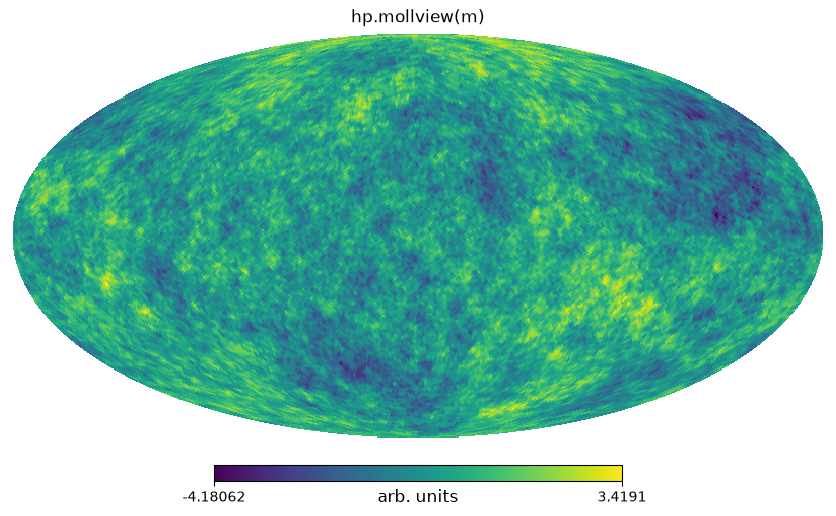

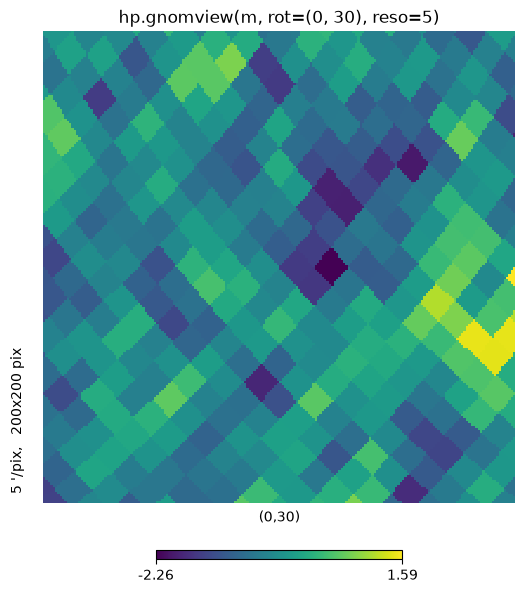

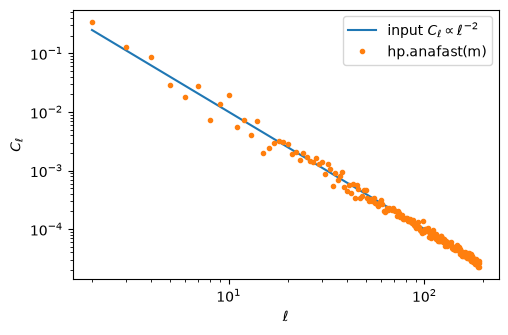

In [74]:
# healpy: a synthetic map from a power-law C_ell, shown with mollview and gnomview, then anafast
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp

nside = 64
ell = np.arange(3 * nside)
cl_in = np.zeros(ell.size)
cl_in[2:] = ell[2:] ** -2.0                         # simple power law, no monopole or dipole
np.random.seed(0)                                   # hp.synfast draws from numpy's global generator
m = hp.synfast(cl_in, nside)
with plt.style.context("default"):
    hp.mollview(m, title="hp.mollview(m)", unit="arb. units")
    hp.gnomview(m, rot=(0, 30), reso=5, xsize=200, title="hp.gnomview(m, rot=(0, 30), reso=5)")
    cl_out = hp.anafast(m)
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    ax.loglog(ell[2:], cl_in[2:], label="input $C_\\ell \\propto \\ell^{-2}$")
    ax.loglog(ell[2:], cl_out[2:], ".", label="hp.anafast(m)")
    ax.set_xlabel(r"$\ell$")
    ax.set_ylabel(r"$C_\ell$")
    ax.legend()
    plt.show()

### Library tour: astropy

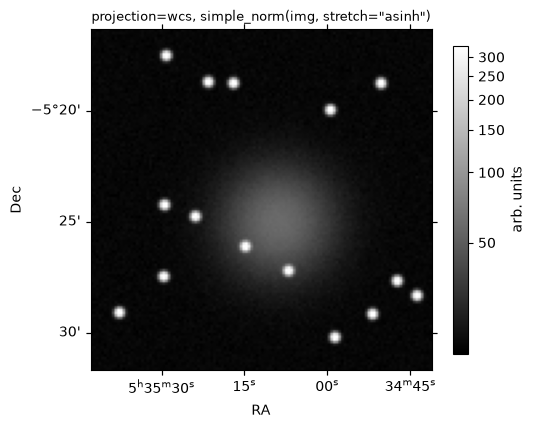

In [75]:
# astropy: a WCS built in code, a synthetic image on RA/Dec axes, and an asinh stretch
import numpy as np
import matplotlib.pyplot as plt
from astropy.wcs import WCS
from astropy.visualization import simple_norm

wcs = WCS(naxis=2)
wcs.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs.wcs.crval = [83.8, -5.4]                        # RA, Dec at the reference pixel [deg]
wcs.wcs.crpix = [64.5, 64.5]
wcs.wcs.cdelt = [-0.002, 0.002]                     # deg per pixel
rng = np.random.default_rng(0)
yy, xx = np.mgrid[0:128, 0:128]
img = 50 * np.exp(-((xx - 70) ** 2 + (yy - 55) ** 2) / 400) + rng.normal(10, 1, xx.shape)
for x0, y0 in rng.uniform(5, 123, (15, 2)):         # a few bright "stars"
    img += 500 * np.exp(-((xx - x0) ** 2 + (yy - y0) ** 2) / 2)
norm = simple_norm(img, stretch="asinh", percent=99.5)
with plt.style.context("default"):
    fig = plt.figure(figsize=(5.5, 5))
    ax = fig.add_subplot(projection=wcs)
    im = ax.imshow(img, origin="lower", cmap="gray", norm=norm)
    ax.set_xlabel("RA")
    ax.set_ylabel("Dec")
    ax.set_title('projection=wcs, simple_norm(img, stretch="asinh")', fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.8, label="arb. units")
    plt.show()

### Library tour: corner

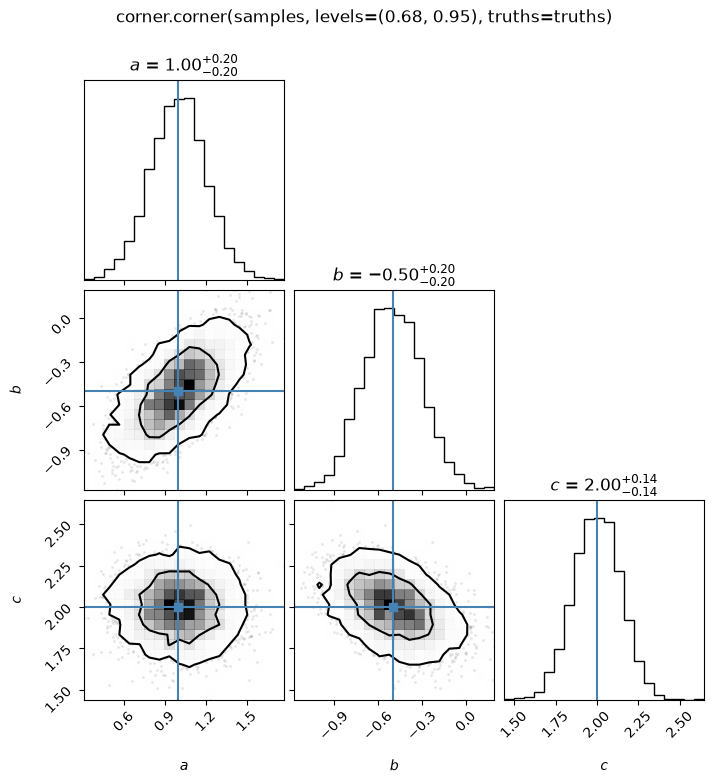

In [76]:
# corner: three correlated parameters with labels, stated contour levels and the true values
import numpy as np
import matplotlib.pyplot as plt
import corner

rng = np.random.default_rng(0)
truths = [1.0, -0.5, 2.0]
cov = 0.04 * np.array([[1.0, 0.6, 0.0], [0.6, 1.0, -0.3], [0.0, -0.3, 0.5]])
samples = rng.multivariate_normal(truths, cov, size=5000)
with plt.style.context("default"):
    fig = corner.corner(samples, labels=[r"$a$", r"$b$", r"$c$"], levels=(0.68, 0.95),
                        truths=truths, show_titles=True)
    fig.suptitle("corner.corner(samples, levels=(0.68, 0.95), truths=truths)", y=1.04)
    plt.show()

### Library tour: seaborn

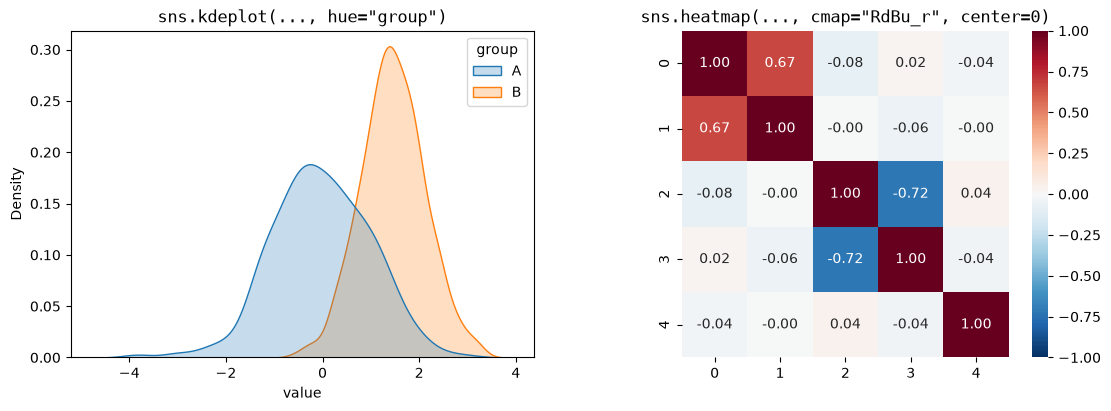

In [77]:
# seaborn: kdeplot of two groups with hue, and a heatmap of a symmetric matrix centred on zero
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(0)
data = {"value": np.r_[rng.normal(0, 1, 500), rng.normal(1.5, 0.7, 500)],
        "group": ["A"] * 500 + ["B"] * 500}
M = rng.normal(size=(200, 5))
M[:, 1] += M[:, 0]                                  # build in some correlations, + and -
M[:, 3] -= M[:, 2]
corr = np.corrcoef(M, rowvar=False)                 # symmetric, values in [-1, 1]
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    sns.kdeplot(data=data, x="value", hue="group", fill=True, ax=ax1)
    ax1.set_title('sns.kdeplot(..., hue="group")', family="monospace")
    sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, ax=ax2)
    ax2.set_title('sns.heatmap(..., cmap="RdBu_r", center=0)', family="monospace")
    plt.show()

## 5. Seems legit: a cautionary tale

> "The code ran. The plot looks fine. It can still be wrong."

1. **The colourbar that lied:** as delivered, the 10-second check, the fix
2. **More ways it goes wrong:** data that isn't yours, silent data loss, limits hiding an outlier, a flipped image origin
3. **Before you trust an AI-made plot:** a checklist

### Demo 1: The colourbar that lied

#### As delivered
*Talking point: three panels, one colourbar, nothing looks off. Ask the room what panel C's peak value is, then panel A's.*

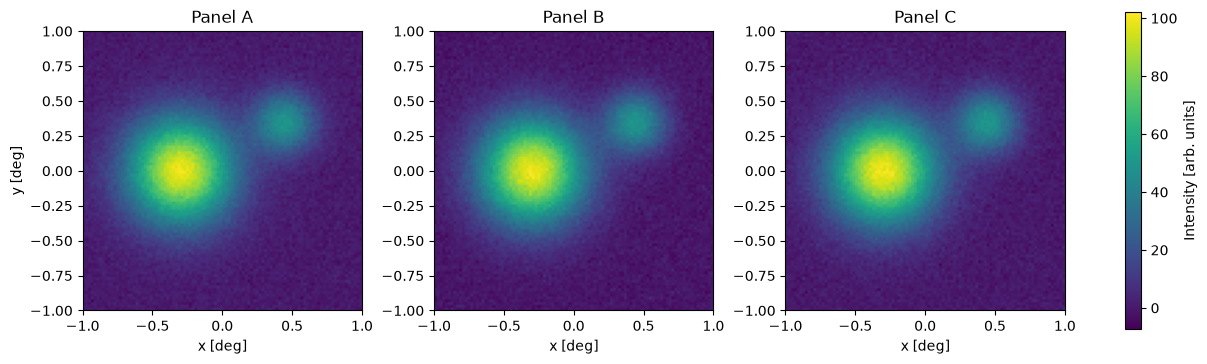

In [78]:
# As delivered: three panels, each autoscaled, one colourbar (it only describes the last image)
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
yy, xx = np.mgrid[-1:1:100j, -1:1:100j]
base = np.exp(-((xx + 0.3) ** 2 + yy ** 2) / 0.15) + 0.5 * np.exp(-((xx - 0.45) ** 2 + (yy - 0.35) ** 2) / 0.05)
base /= base.max()
scales = [1, 10, 100]
panels = [s * (base + 0.02 * rng.normal(size=base.shape)) for s in scales]

with plt.style.context("default"):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
    for ax, img, name in zip(axes, panels, "ABC"):
        im = ax.imshow(img, origin="lower", cmap="viridis", extent=[-1, 1, -1, 1])
        ax.set_title(f"Panel {name}")
        ax.set_xlabel("x [deg]")
    axes[0].set_ylabel("y [deg]")
    fig.colorbar(im, ax=axes, label="Intensity [arb. units]")
    plt.show()

#### The 10-second check

In [79]:
# The reveal: every panel has its own colour limits, the colourbar only matches Panel C
print([im.get_clim() for ax in axes for im in ax.images])

[(-0.07796687641037334, 1.0340425524309138), (-0.6314029993416598, 10.308913395177619), (-7.457107181685843, 102.09359093000008)]


#### The fix
*Talking point: one shared vmin/vmax for every panel. Now A is nearly black, which is the truth.*

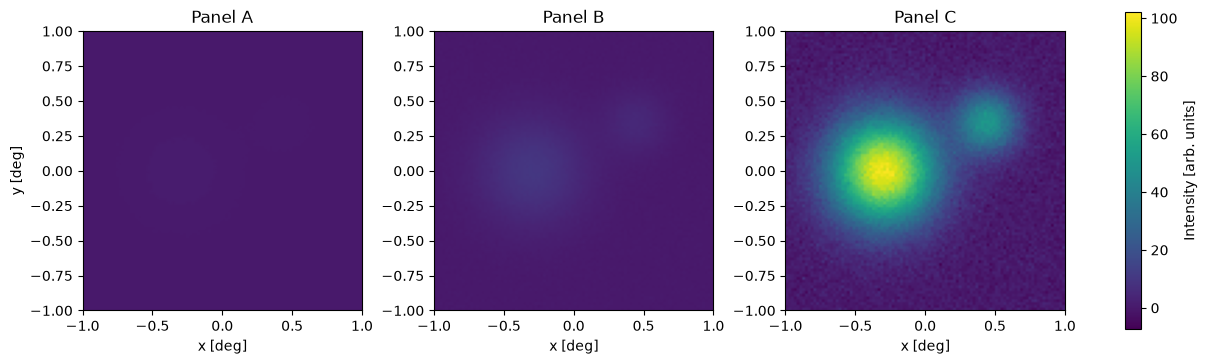

[(-7.457107181685843, 102.09359093000008), (-7.457107181685843, 102.09359093000008), (-7.457107181685843, 102.09359093000008)]


In [80]:
# The fix: one vmin/vmax computed across all panels and passed to every imshow
import numpy as np
import matplotlib.pyplot as plt

vmin = min(img.min() for img in panels)
vmax = max(img.max() for img in panels)
with plt.style.context("default"):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
    for ax, img, name in zip(axes, panels, "ABC"):
        im = ax.imshow(img, origin="lower", cmap="viridis", extent=[-1, 1, -1, 1], vmin=vmin, vmax=vmax)
        ax.set_title(f"Panel {name}")
        ax.set_xlabel("x [deg]")
    axes[0].set_ylabel("y [deg]")
    fig.colorbar(im, ax=axes, label="Intensity [arb. units]")
    plt.show()
print([im.get_clim() for ax in axes for im in ax.images])

### Demo 2: More ways it goes wrong

#### a. Data that isn't yours
*Talking point: when the real file failed to load, the assistant "helpfully" generated stand-in data.*

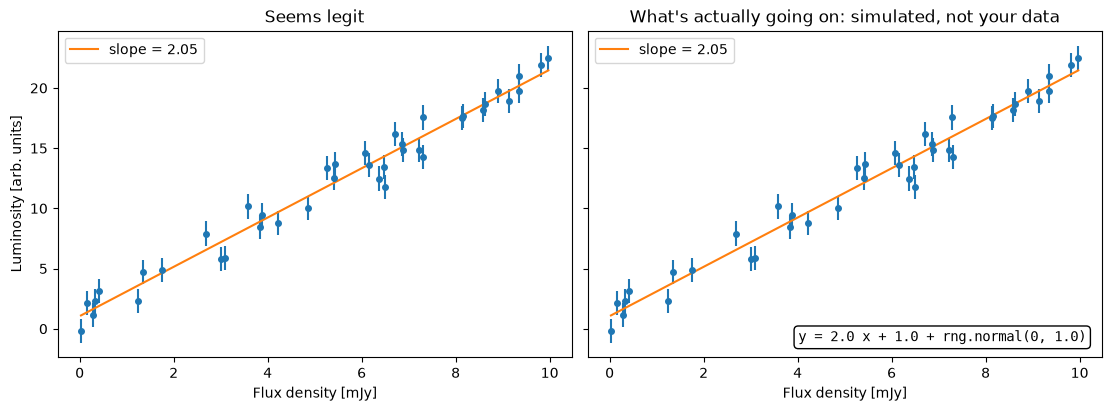

In [81]:
# Data that isn't yours: a tidy scatter that was simulated, not measured
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = rng.uniform(0, 10, 40)
y = 2.0 * x + 1.0 + rng.normal(0, 1.0, x.size)        # the "measurements"
fit = np.polyfit(x, y, 1)
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
    for ax in (ax1, ax2):
        ax.errorbar(x, y, yerr=1.0, fmt="o", ms=4)
        ax.plot(np.sort(x), np.polyval(fit, np.sort(x)), label=f"slope = {fit[0]:.2f}")
        ax.set_xlabel("Flux density [mJy]")
        ax.legend(loc="upper left")
    ax1.set_ylabel("Luminosity [arb. units]")
    ax1.set_title("Seems legit")
    ax2.set_title("What's actually going on: simulated, not your data")
    ax2.text(0.97, 0.05, "y = 2.0 x + 1.0 + rng.normal(0, 1.0)", transform=ax2.transAxes,
             ha="right", family="monospace", bbox=dict(boxstyle="round", facecolor="white"))
    plt.show()

#### b. Silent data loss
*Talking point: a log axis drops zeros and negatives without a single warning.*

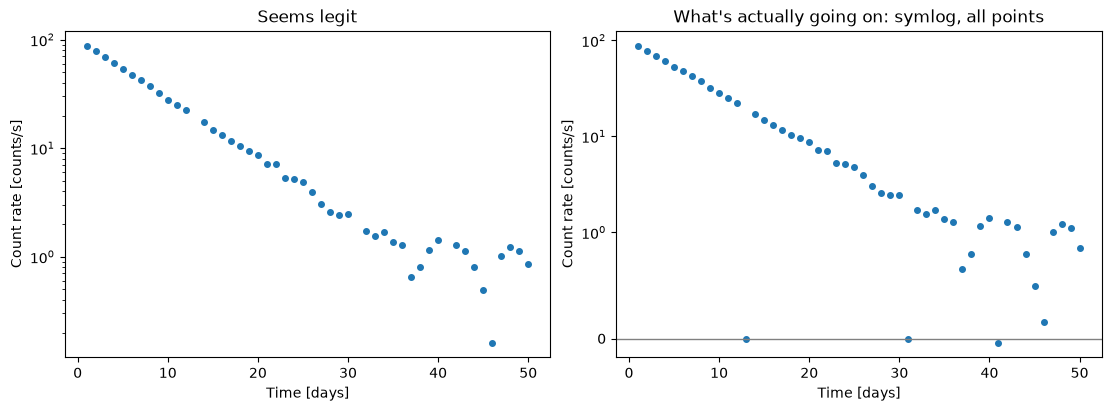

points in the data: 50, points visible on the log axis: 47


In [82]:
# Silent data loss: a log axis hides every value <= 0; symlog shows them all
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = np.linspace(1, 50, 50)
y = 100 * np.exp(-x / 8) + rng.normal(0, 0.5, x.size)   # decays into noise, so it crosses zero
y[[12, 30]] = 0.0
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    ax1.plot(x, y, "o", ms=4)
    ax1.set_yscale("log")
    ax1.set_title("Seems legit")
    ax2.plot(x, y, "o", ms=4)
    ax2.set_yscale("symlog", linthresh=1)
    ax2.axhline(0, color="0.5", lw=1)
    ax2.set_title("What's actually going on: symlog, all points")
    for ax in (ax1, ax2):
        ax.set_xlabel("Time [days]")
        ax.set_ylabel("Count rate [counts/s]")
    plt.show()
print(f"points in the data: {y.size}, points visible on the log axis: {np.sum(y > 0)}")

#### c. Limits hiding an outlier
*Talking point: someone set the y-limits to "make it look nicer", and the most interesting point vanished.*

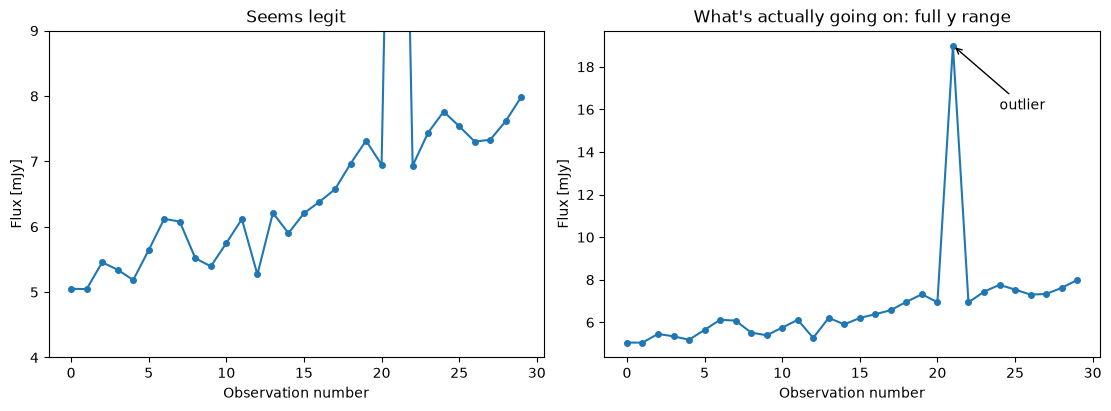

In [83]:
# Limits hiding an outlier: a tight ylim crops the one point that matters
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
x = np.arange(30)
y = 5 + 0.1 * x + rng.normal(0, 0.4, x.size)
y[21] = 19.0                                          # the outlier
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax in (ax1, ax2):
        ax.plot(x, y, "o-", ms=4)
        ax.set_xlabel("Observation number")
        ax.set_ylabel("Flux [mJy]")
    ax1.set_ylim(4, 9)
    ax1.set_title("Seems legit")
    ax2.annotate("outlier", xy=(21, 19), xytext=(24, 16), arrowprops=dict(arrowstyle="->"))
    ax2.set_title("What's actually going on: full y range")
    plt.show()

#### d. Flipped image origin
*Talking point: the array is stored with row 0 at the bottom (as in FITS), so imshow's default draws it upside down.*

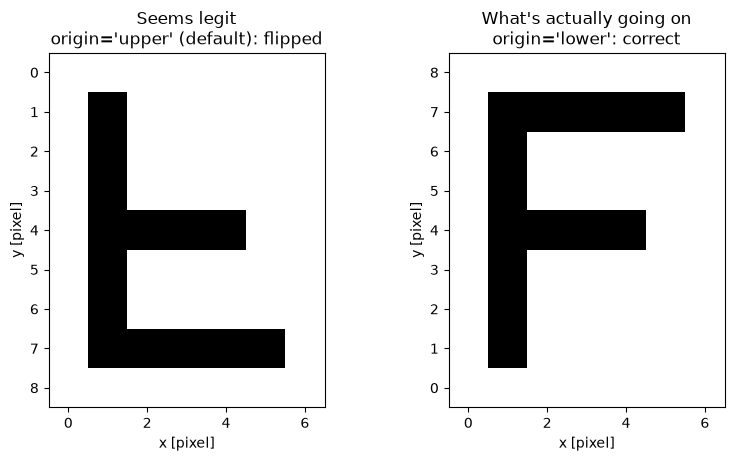

In [84]:
# Flipped image origin: data stored with row 0 at the bottom needs origin="lower"
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((9, 7))            # img[y, x], y increasing upwards
img[1:8, 1] = 1                   # the stem of an "F"
img[7, 1:6] = 1                   # top bar
img[4, 1:5] = 1                   # middle bar
with plt.style.context("default"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), layout="constrained")
    ax1.imshow(img, cmap="gray_r")
    ax1.set_title("Seems legit\norigin='upper' (default): flipped")
    ax2.imshow(img, cmap="gray_r", origin="lower")
    ax2.set_title("What's actually going on\norigin='lower': correct")
    for ax in (ax1, ax2):
        ax.set_xlabel("x [pixel]")
        ax.set_ylabel("y [pixel]")
    plt.show()

### Before you trust an AI-made plot

- Did I ask for the check as well as the plot?
- Did I read the code, not just look at the picture?
- Are the colour limits, axis limits and scales what I intended?
- Does the number of points match my data?
- Is the data mine, and not simulated?
- Did I test with an input where I know the answer?
- Do a few values match the raw numbers?
- Can I explain every line to a reviewer?

**The plot isn't done when it renders. It's done when you've checked it.**

## 6. Bonus: interactive plots

Static is for papers. Interactive is for exploring and sharing. Details in the cheat sheet, section 6.
These cells need optional packages and skip themselves if they are missing.
They do not use the style file.

Hover over the outlier.

In [85]:
# Hover: Plotly Express scatter, coloured by group; hover shows each point's name and values
import numpy as np
try:
    import plotly.express as px
    import pandas as pd
except ImportError:
    print("Optional: pip install plotly nbformat to run this demo. See the cheat sheet, section 6.")
else:
    rng = np.random.default_rng(0)
    n = 200
    centres = {"Survey A": (0.5, 18.0), "Survey B": (1.0, 19.0), "Survey C": (1.5, 18.5)}
    group = rng.choice(list(centres), n)
    colour = np.array([centres[g][0] for g in group]) + rng.normal(0, 0.15, n)
    mag = np.array([centres[g][1] for g in group]) + rng.normal(0, 0.4, n)
    colour[0], mag[0] = 2.8, 15.5                    # the outlier
    df = pd.DataFrame({"name": [f"SRC-{i:03d}" for i in range(n)], "group": group,
                       "colour index": colour, "magnitude": mag})
    fig = px.scatter(df, x="colour index", y="magnitude", color="group", hover_name="name",
                     hover_data={"colour index": ":.2f", "magnitude": ":.2f"}, template="simple_white")
    fig.update_yaxes(autorange="reversed")           # brighter is up, as usual for magnitudes
    fig.show()

Optional: pip install plotly nbformat to run this demo. See the cheat sheet, section 6.


Zoom in and pan.

In [86]:
# Zoom: px.imshow of a synthetic image (a few Gaussian blobs plus noise)
import numpy as np
try:
    import plotly.express as px
except ImportError:
    print("Optional: pip install plotly nbformat to run this demo. See the cheat sheet, section 6.")
else:
    rng = np.random.default_rng(0)
    yy, xx = np.mgrid[-1:1:200j, -1:1:200j]
    img = 0.05 * rng.normal(size=xx.shape)
    for x0, y0, w, a in [(-0.4, -0.2, 0.05, 1.0), (0.3, 0.4, 0.01, 0.8), (0.5, -0.5, 0.002, 1.5), (-0.6, 0.6, 0.02, 0.5)]:
        img += a * np.exp(-((xx - x0) ** 2 + (yy - y0) ** 2) / w)
    fig = px.imshow(img, origin="lower", color_continuous_scale="viridis",
                    labels={"x": "x [pixel]", "y": "y [pixel]", "color": "Intensity"})
    fig.show()

Optional: pip install plotly nbformat to run this demo. See the cheat sheet, section 6.


The same stretch idea as the sky map, live.

In [87]:
# Slider: ipywidgets interact re-draws an arcsinh stretch, np.arcsinh(image / s), as you move s
import numpy as np
import matplotlib.pyplot as plt
try:
    from ipywidgets import interact, FloatSlider
except ImportError:
    print("Optional: pip install ipywidgets to run this demo. See the cheat sheet, section 6.")
else:
    rng = np.random.default_rng(0)
    yy, xx = np.mgrid[-1:1:150j, -1:1:150j]
    image = (5000 * np.exp(-(xx ** 2 + yy ** 2) / 0.003)                      # bright, compact source
             + 40 * np.exp(-((xx + 0.35) ** 2 + (yy - 0.25) ** 2) / 0.12)     # faint, extended emission
             + rng.normal(0, 2, xx.shape))

    def show(s):
        fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
        im = ax.imshow(np.arcsinh(image / s), origin="lower", cmap="gray", extent=[-1, 1, -1, 1])
        fig.colorbar(im, ax=ax, label="asinh(I / s)")
        ax.set_title(f"s = {s:g}")
        plt.show()

    interact(show, s=FloatSlider(min=10, max=3000, step=10, value=300, description="s"))

interactive(children=(FloatSlider(value=300.0, description='s', max=3000.0, min=10.0, step=10.0), Output()), _…

When static is better: papers, theses, and anything printed. Make the static version with your style file.